# CHƯƠNG 3. DỮ LIỆU VÀ PHƯƠNG PHÁP XỬ LÝ

**Đề tài:** Phân tích dữ liệu đơn hàng và dự đoán nguy cơ giao hàng trễ trong thương mại điện tử  
**Người thực hiện:** Lam Linh — Nhóm 02

Chương này trình bày nguồn dữ liệu Olist, quá trình làm sạch và tích hợp chín bảng, quy tắc tạo nhãn giao trễ, kết quả phân tích khám phá và bộ đặc trưng đầu vào. Dữ liệu được tổ chức theo nguyên tắc một dòng cho mỗi đơn hàng. Mốc dự đoán là thời điểm đơn được phê duyệt (`order_approved_at`), do đó thông tin xuất hiện sau mốc này chỉ phục vụ tạo nhãn hoặc phân tích hồi cứu.

Nội dung gồm năm phần: **3.1 Nguồn và cấu trúc dữ liệu; 3.2 Tích hợp và làm sạch; 3.3 Nhãn và chọn mẫu; 3.4 Phân tích khám phá; 3.5 Xây dựng đặc trưng và kiểm soát rò rỉ thông tin.**


## Thiết lập môi trường

Cài các thư viện trong `requirements.txt` và đặt 9 CSV gốc vào `data/raw/` theo hướng dẫn dữ liệu. Chạy lần lượt các cell từ trên xuống. Notebook lưu bảng dữ liệu đã xử lý ở data/processed/ và kết quả kiểm tra, hình minh họa ở reports/.


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display, Markdown

NAMES = {
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'translation': 'product_category_name_translation.csv',
}
HERE = Path.cwd().resolve()
root = next((parent for parent in (HERE, *HERE.parents)
             if (parent / 'data' / 'raw').is_dir()), None)
if root is None:
    raise FileNotFoundError('Mở notebook từ repository có thư mục data/raw/.')
ROOT = root
RAW = ROOT / 'data' / 'raw'
missing = []
pointers = []
for filename in NAMES.values():
    path = RAW / filename
    if not path.is_file():
        missing.append(filename)
        continue
    with path.open('rb') as stream:
        if stream.readline(80).startswith(b'version https://git-lfs.github.com/spec/v1'):
            pointers.append(filename)
if missing or pointers:
    details = []
    if missing:
        details.append('Thiếu CSV: ' + ', '.join(missing))
    if pointers:
        details.append('Chỉ có con trỏ Git LFS: ' + ', '.join(pointers))
    raise FileNotFoundError(
        ' | '.join(details)
        + '. Tải bộ Olist từ Kaggle, giải nén 9 CSV vào data/raw/ và chạy lại.'
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.labels import make_late_label

PROCESSED = ROOT / 'data' / 'processed'
CLEAN_DIR = PROCESSED / 'cleaned'
TABLES = ROOT / 'reports' / 'tables'
FIGURES = ROOT / 'reports' / 'figures'
for path in (CLEAN_DIR, TABLES, FIGURES):
    path.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 18)
plt.rcParams['figure.dpi'] = 110
LOG = []
NARRATIVES = {}
def explain(key, text):
    NARRATIVES[key] = text
    display(Markdown(text))

def md_table(frame):
    def esc(x):
        return str(x).replace('|', '/').replace('\n', ' ')
    rows = ['| ' + ' | '.join(map(esc, frame.columns)) + ' |',
            '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
    rows += ['| ' + ' | '.join(map(esc, row)) + ' |' for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(rows)


def record(table, rule, affected, action):
    LOG.append({'table': table, 'rule': rule, 'affected': int(affected), 'action': action})

def start_clean(name):
    d = raw[name].copy()
    duplicate = d.duplicated()
    record(name, 'exact_duplicate_rows', duplicate.sum(), 'remove_exact_duplicates')
    d = d.loc[~duplicate].copy()
    for col in d.select_dtypes(include=['object', 'string']).columns:
        s = d[col].astype('string')
        d[col] = s.str.strip().replace('', pd.NA)
    return d

def require_key(d, columns, name):
    missing = d[columns].isna().any(axis=1)
    duplicate = d.duplicated(columns, keep=False)
    record(name, 'missing_key', missing.sum(), 'stop_if_present')
    record(name, 'duplicate_key_rows', duplicate.sum(), 'stop_if_present')
    if missing.any() or duplicate.any():
        d.loc[missing | duplicate].to_csv(TABLES / f'{name}_key_conflicts.csv', index=False)
        raise ValueError(f'{name}: khóa thiếu/trùng. Xem bảng xung đột; không tự giữ dòng đầu.')

def parse_dates(d, cols, name):
    for col in cols:
        source = d[col].copy()
        parsed = pd.to_datetime(source, errors='coerce')
        failed = source.notna() & parsed.isna()
        record(name, 'invalid_datetime:' + col, failed.sum(), 'coerce_to_NaT_and_report')
        d[col] = parsed

def to_number(d, cols, name):
    for col in cols:
        source = d[col].copy()
        converted = pd.to_numeric(source, errors='coerce')
        record(name, 'numeric_parse_failure:' + col,
               (source.notna() & converted.isna()).sum(), 'coerce_to_NA_and_report')
        d[col] = converted

def normalize_location(d, prefix, name):
    # Không bỏ dấu/đổi tên địa danh tùy ý. Mã ZIP prefix luôn là chuỗi 5 chữ số.
    zip_col, city_col, state_col = prefix + '_zip_code_prefix', prefix + '_city', prefix + '_state'
    s = d[zip_col].astype('string').str.strip()
    valid = s.str.fullmatch(r'\d{1,5}').fillna(False)
    d['qa_invalid_zip'] = ~valid
    record(name, 'invalid_zip_prefix', (~valid).sum(), 'set_NA_keep_flag')
    d[zip_col] = s.where(valid).str.zfill(5)
    d[city_col] = d[city_col].astype('string').str.normalize('NFC').str.lower().str.replace(r'\s+', ' ', regex=True)
    d[state_col] = d[state_col].astype('string').str.upper()
    states = set('AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO'.split())
    d['qa_invalid_state'] = ~d[state_col].isin(states)
    record(name, 'invalid_state', d['qa_invalid_state'].sum(), 'keep_flag_for_review')
    return d

print('Thư mục dự án:', ROOT.name, '| đầu vào:', RAW.relative_to(ROOT))
print('Python:', platform.python_version(), '| pandas:', pd.__version__)


## 3.1. Nguồn và cấu trúc dữ liệu

Nghiên cứu sử dụng **Brazilian E-Commerce Public Dataset by Olist**, công bố trên Kaggle [1]. Bộ dữ liệu mô tả hoạt động đặt hàng tại Brazil trong giai đoạn 2016–2018, gồm thông tin đơn hàng, khách hàng, người bán, sản phẩm, thanh toán, đánh giá và địa lý. Trang nguồn công bố giấy phép **CC BY-NC-SA 4.0**.

Dữ liệu đầu vào gồm chín tệp CSV. Bảng `orders` là trung tâm để xác định trạng thái, thời gian và nhãn của đơn hàng. Các bảng còn lại cung cấp thông tin chi tiết để làm sạch, đối chiếu và phân tích. Mã SHA256 của từng tệp được lưu trong `source_manifest.csv` nhằm nhận diện chính xác dữ liệu sử dụng.

**Tải và tái lập dữ liệu.** Tải bộ Olist từ trang Kaggle [1] và giải nén 9 CSV vào thư mục data/raw/. Nếu đã cài Git LFS, có thể lấy các tệp có sẵn trên main bằng lệnh git lfs pull. Đối chiếu phiên bản dữ liệu theo bảng source_manifest.csv.


### 3.1.1. Kiểm kê chín bảng

**Bảng 3.1. Kích thước và chất lượng dữ liệu gốc**

*Nguồn: Nhóm tính từ 9 CSV của Olist [1].*

Bảng kiểm kê ghi số dòng, số cột, dòng trùng hoàn toàn và ô thiếu. Bảng hồ sơ từng cột lưu trong reports/tables/raw_column_profile.csv.


In [ ]:
raw = {}
source_records = []
for name, filename in NAMES.items():
    path = RAW / filename
    columns = pd.read_csv(path, nrows=0).columns
    string_cols = {c: 'string' for c in columns
                   if (c.endswith('_id') and c != 'order_item_id') or 'zip_code_prefix' in c}
    raw[name] = pd.read_csv(path, dtype=string_cols)
    source_records.append({'table': name, 'file': filename,
                           'bytes': path.stat().st_size,
                           'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
profile = pd.DataFrame([{
    'table': name, 'rows': len(d), 'columns': len(d.columns),
    'duplicate_rows': int(d.duplicated().sum()),
    'missing_cells': int(d.isna().sum().sum())
} for name, d in raw.items()])
column_profile = pd.DataFrame([{
    'table': name, 'column': c, 'dtype': str(d[c].dtype),
    'missing': int(d[c].isna().sum()), 'missing_pct': round(100*d[c].isna().mean(), 3),
    'n_unique': int(d[c].nunique())
} for name, d in raw.items() for c in d.columns])
profile.to_csv(TABLES / 'raw_profile.csv', index=False)
column_profile.to_csv(TABLES / 'raw_column_profile.csv', index=False)
pd.DataFrame(source_records).to_csv(TABLES / 'source_manifest.csv', index=False)
table_names = {
    'orders': 'Đơn hàng', 'items': 'Chi tiết đơn', 'customers': 'Khách hàng',
    'sellers': 'Người bán', 'products': 'Sản phẩm', 'payments': 'Thanh toán',
    'reviews': 'Đánh giá', 'geolocation': 'Địa lý', 'translation': 'Dịch danh mục',
}
profile_vi = profile.assign(table=profile['table'].map(table_names)).rename(columns={
    'table': 'Bảng', 'rows': 'Số dòng', 'columns': 'Số cột',
    'duplicate_rows': 'Dòng trùng', 'missing_cells': 'Ô thiếu',
})
display(profile_vi)


Nhận xét: geolocation có nhiều dòng nhất (1.000.163), trong đó 261.831 dòng trùng hoàn toàn. reviews có 145.903 ô thiếu, tập trung ở tiêu đề và nội dung bình luận; đây là các trường không bắt buộc. orders còn 4.908 ô thiếu, products còn 2.448 ô thiếu. Vì vậy cần làm sạch theo ý nghĩa của từng cột, không xóa tất cả dòng có giá trị rỗng.

Khóa nối chính: order_id ở orders; cặp order_id–`order_item_id` ở items; customer_id, product_id, seller_id ở các bảng tương ứng. Một đơn có thể có nhiều sản phẩm hoặc nhiều lần thanh toán nên không xem order_id lặp ở những bảng này là lỗi.


### 3.1.2. Sơ đồ quan hệ dữ liệu

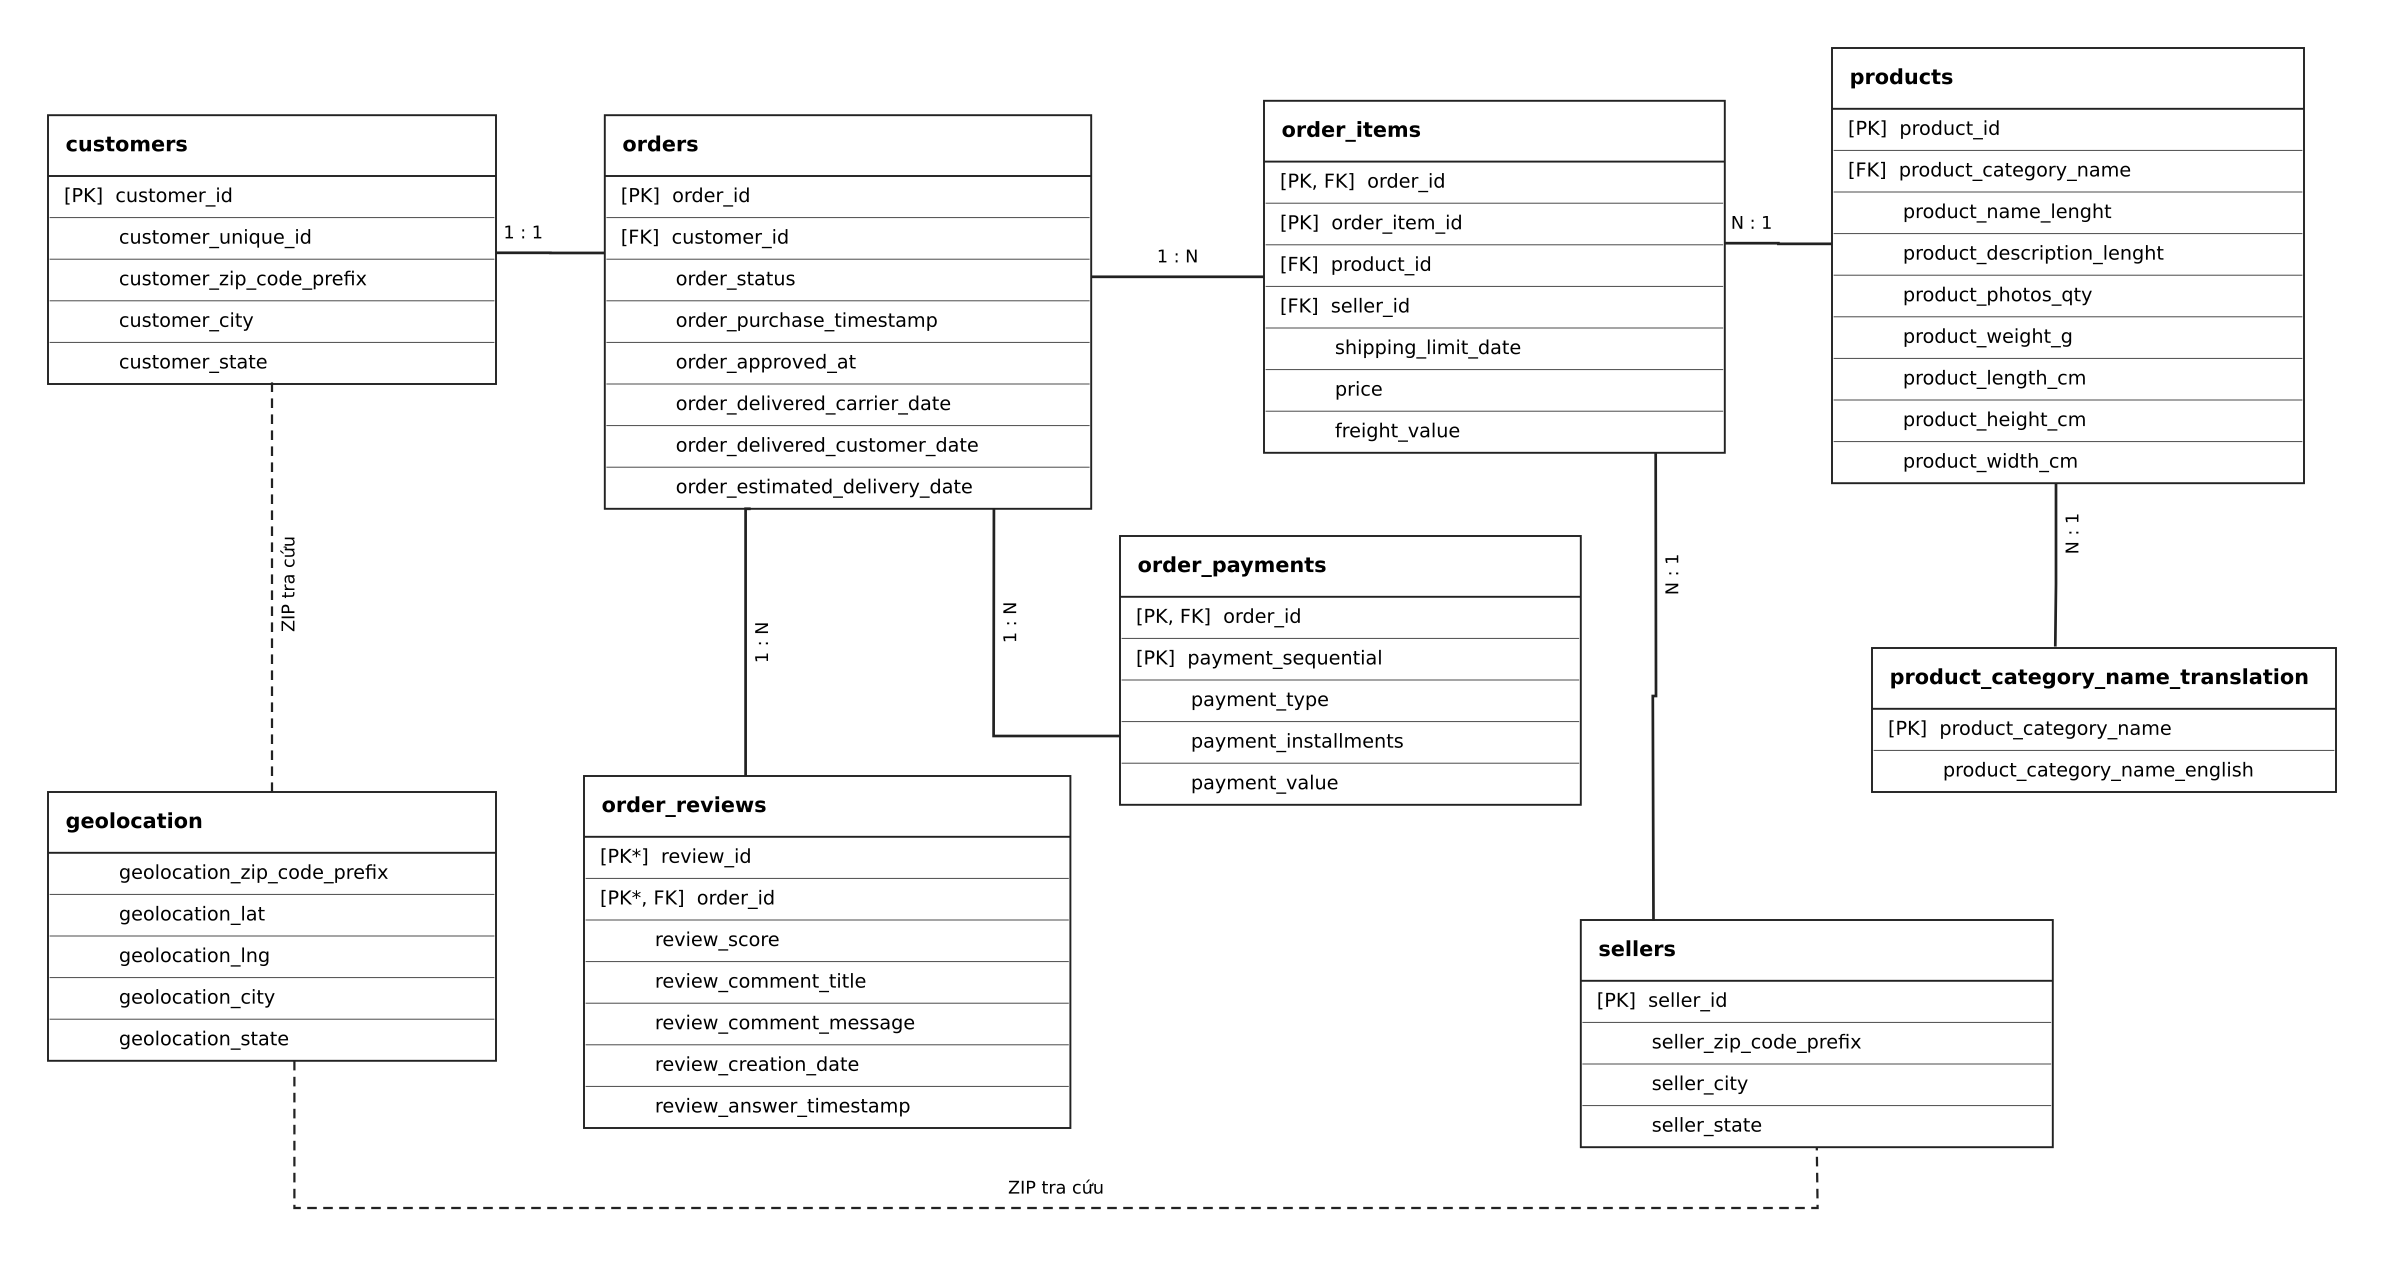

*Hình 3.1. Sơ đồ ERD Olist do Lam Linh thiết kế bằng draw.io.*

Ký hiệu PK chỉ khóa chính; FK chỉ trường liên kết; PK* ở bảng đánh giá là cặp khóa được kiểm tra trong dữ liệu. Quan hệ 1:N cho biết một bản ghi có thể liên quan đến nhiều bản ghi ở bảng khác. Liên kết ZIP là tra cứu địa lý, không phải khóa duy nhất của bảng geolocation gốc.


In [ ]:
cardinality = pd.DataFrame([
 {'quan_he':'customers → orders','khoa':'customer_id','cap_du_lieu':'1:1 quan sát trong bộ dữ liệu',
  'so_khoa_con_lap':int(raw['orders']['customer_id'].duplicated().sum())},
 {'quan_he':'orders → items','khoa':'order_id','cap_du_lieu':'1:N', 'so_khoa_con_lap':int(raw['items']['order_id'].duplicated().sum())},
 {'quan_he':'orders → payments','khoa':'order_id','cap_du_lieu':'1:N','so_khoa_con_lap':int(raw['payments']['order_id'].duplicated().sum())},
 {'quan_he':'orders → reviews','khoa':'order_id','cap_du_lieu':'1:N','so_khoa_con_lap':int(raw['reviews']['order_id'].duplicated().sum())},
])
display(cardinality)
cardinality.to_csv(TABLES/'cardinality_audit.csv',index=False)


Về nghiệp vụ, một người mua có thể phát sinh nhiều đơn hàng. Tuy nhiên, Olist cấp một `customer_id` riêng cho mỗi đơn. Vì vậy, quan hệ customers–orders theo `customer_id` trong dữ liệu đang xét là **1:1**, còn việc nhận diện người mua lặp phải dựa vào `customer_unique_id`. Sơ đồ biểu diễn quan hệ theo khóa customer_id của các bảng; quan hệ người mua–đơn hàng theo customer_unique_id vẫn là 1:N.

Khóa của items là cặp `order_id, order_item_id`; khóa của payments là `order_id, payment_sequential`. Với reviews, cặp `review_id, order_id` được kiểm tra thay vì ép riêng `review_id` phải duy nhất. Các bảng giao dịch phải được tổng hợp trước khi nối về cấp đơn hàng.

Geolocation có nhiều tọa độ cho cùng ZIP prefix nên được tổng hợp thành một dòng/ZIP trước khi tra cứu. Translation được dùng để kiểm tra tên danh mục, nhưng không phải danh mục nào cũng có bản dịch. Hai bảng này và reviews được xử lý riêng; chúng không tạo feature trong bộ baseline của nghiên cứu.


## 3.2. Tích hợp và làm sạch dữ liệu

Quy trình gồm chuẩn hóa chuỗi và kiểu dữ liệu, kiểm tra khóa, xử lý dòng trùng hoàn toàn, đánh dấu các giá trị bất thường, sau đó tổng hợp và kết nối các bảng. Dữ liệu thiếu được xử lý theo ý nghĩa từng trường: không tự điền ngày giao, không xóa đánh giá chỉ vì thiếu bình luận và không xem mã đơn lặp trong bảng items là lỗi.

Các cờ QA giữ lại dấu vết của những trường hợp bất thường. Những phép điền thiếu, mã hóa và chuẩn hóa có học từ dữ liệu được tách khỏi bước này để chỉ fit trên tập Train ở Chương 4.


### 3.2.1. Đơn hàng


In [ ]:
orders = start_clean('orders')
require_key(orders, ['order_id'], 'orders')
orders['order_status'] = orders['order_status'].astype('string').str.lower()
valid_status = {'delivered', 'shipped', 'canceled', 'unavailable', 'invoiced', 'processing', 'created', 'approved'}
orders['qa_unknown_status'] = ~orders['order_status'].isin(valid_status)
parse_dates(orders, ['order_purchase_timestamp', 'order_approved_at',
                    'order_delivered_carrier_date', 'order_delivered_customer_date',
                    'order_estimated_delivery_date'], 'orders')
orders['qa_approved_before_purchase'] = orders['order_approved_at'] < orders['order_purchase_timestamp']
orders['qa_carrier_before_approved'] = orders['order_delivered_carrier_date'] < orders['order_approved_at']
orders['qa_delivery_before_carrier'] = orders['order_delivered_customer_date'] < orders['order_delivered_carrier_date']
orders['qa_delivery_before_approved'] = orders['order_delivered_customer_date'] < orders['order_approved_at']
orders['qa_delivery_before_purchase'] = orders['order_delivered_customer_date'] < orders['order_purchase_timestamp']
orders['qa_estimate_before_purchase'] = orders['order_estimated_delivery_date'].dt.normalize() < orders['order_purchase_timestamp'].dt.normalize()
for c in orders.filter(like='qa_').columns:
    record('orders', c, orders[c].sum(), 'keep_flag_review_before_changing_cohort')
display(orders['order_status'].value_counts(dropna=False).rename('orders').to_frame())
display(orders.filter(like='qa_').sum().rename('flagged_rows').to_frame())


Nhận xét: Có 96.478/99.441 đơn ở trạng thái delivered. Không có trạng thái lạ, nhưng có 1.359 bản ghi bàn giao vận chuyển trước thời điểm duyệt, 23 bản ghi giao khách trước khi bàn giao vận chuyển và 61 bản ghi giao khách trước khi duyệt. Các nhóm này có thể trùng nhau nên không cộng thành tổng số đơn lỗi. Các cờ được giữ để kiểm tra độ nhạy của mẫu tại mục 3.3; không tự sửa các mốc thời gian gốc.


### 3.2.2. Items – sản phẩm trong đơn hàng
Kiểm tra khóa ghép, giá, phí vận chuyển và ngày giới hạn gửi hàng.


In [ ]:
items = start_clean('items')
to_number(items, ['order_item_id', 'price', 'freight_value'], 'items')
require_key(items, ['order_id', 'order_item_id'], 'items')
parse_dates(items, ['shipping_limit_date'], 'items')
items['qa_invalid_item_number'] = items['order_item_id'].isna() | (items['order_item_id'] < 1) | (items['order_item_id'] % 1 != 0)
items['qa_nonpositive_price'] = items['price'].isna() | (items['price'] <= 0)
items['qa_negative_freight'] = items['freight_value'] < 0
items['qa_missing_product_or_seller'] = items[['product_id', 'seller_id']].isna().any(axis=1)
for c in items.filter(like='qa_').columns:
    record('items', c, items[c].sum(), 'keep_flag_for_review')
display(items[['price', 'freight_value']].describe(percentiles=[.5,.95,.99]))
print('Item có phí vận chuyển bằng 0, giữ lại:', int(items['freight_value'].eq(0).sum()))


Nhận xét: Giá sản phẩm có trung vị 74,99 BRL và trung bình 120,65 BRL, cho thấy có những mặt hàng giá cao kéo trung bình lên. Có 383 dòng phí vận chuyển bằng 0; các dòng này được giữ vì chưa có căn cứ xem phí 0 là sai. Không phát hiện giá âm trong thống kê hiển thị.


### 3.2.3. Customers – khách hàng
Kiểm tra khóa khách hàng, chuẩn hóa mã ZIP, tên thành phố và mã bang.


In [ ]:
customers = start_clean('customers')
require_key(customers, ['customer_id'], 'customers')
customers = normalize_location(customers, 'customer', 'customers')
print('Số bản ghi customer:', len(customers))
print('Số khách phân biệt theo customer_unique_id:', customers['customer_unique_id'].nunique())
display(customers[['qa_invalid_zip','qa_invalid_state']].sum().rename('flagged_rows').to_frame())


Nhận xét: Bảng có 99.441 bản ghi khách hàng, tương ứng 96.096 mã customer_unique_id khác nhau. Một người có thể mua nhiều đơn, nên không xóa các mã khách hàng lặp theo customer_unique_id. Không phát hiện ZIP hoặc mã bang không hợp lệ theo quy tắc đang kiểm tra.


### 3.2.4. Sellers – người bán
Chuẩn hóa thông tin địa lý và kiểm tra seller_id.


In [ ]:
sellers = start_clean('sellers')
require_key(sellers, ['seller_id'], 'sellers')
sellers = normalize_location(sellers, 'seller', 'sellers')
print('Số người bán:', len(sellers))
display(sellers[['qa_invalid_zip','qa_invalid_state']].sum().rename('flagged_rows').to_frame())


Nhận xét: Có 3.095 người bán. Không ghi nhận mã ZIP hoặc mã bang không hợp lệ theo phép kiểm tra hiện tại, nên không có bản ghi nào bị loại ở bước này.


### 3.2.5. Products – sản phẩm
Kiểm tra các thuộc tính mô tả sản phẩm; giữ nguyên cột gốc và đánh dấu các giá trị bất thường.


In [ ]:
products = start_clean('products')
require_key(products, ['product_id'], 'products')
product_numeric = ['product_name_lenght','product_description_lenght','product_photos_qty',
                   'product_weight_g','product_length_cm','product_height_cm','product_width_cm']
to_number(products, product_numeric, 'products')
products['qa_missing_category'] = products['product_category_name'].isna()
for c in ['product_weight_g','product_length_cm','product_height_cm','product_width_cm']:
    products[c + '_raw'] = products[c]
    invalid = products[c].notna() & (products[c] <= 0)
    products['qa_nonpositive_' + c] = invalid
    products.loc[invalid, c] = np.nan
    record('products', 'nonpositive:' + c, invalid.sum(), 'set_NA_keep_original_raw_column')
for c in ['product_name_lenght','product_description_lenght','product_photos_qty']:
    products['qa_invalid_' + c] = products[c].notna() & ((products[c] < 0) | (products[c] % 1 != 0))
display(products[['product_category_name'] + product_numeric].isna().sum().rename('missing_after').to_frame())
print('Trọng lượng 0/âm đã chuyển thành thiếu:', int(products['qa_nonpositive_product_weight_g'].sum()))


Nhận xét: Có 610 sản phẩm thiếu danh mục và đồng thời thiếu các thông tin độ dài tên, mô tả, số ảnh. Trọng lượng ban đầu thiếu 2 dòng; thêm 4 dòng có trọng lượng bằng 0 hoặc âm được chuyển thành thiếu, nên sau xử lý có 6 dòng thiếu trọng lượng. Không tự điền giá trị vì chưa có cơ sở xác định trọng lượng thực tế.


### 3.2.6. Payments – thanh toán
Kiểm tra thứ tự thanh toán, hình thức thanh toán, số kỳ và giá trị tiền.


In [ ]:
payments = start_clean('payments')
to_number(payments, ['payment_sequential','payment_installments','payment_value'], 'payments')
require_key(payments, ['order_id','payment_sequential'], 'payments')
payments['payment_type'] = payments['payment_type'].astype('string').str.lower()
payments['qa_unknown_payment_type'] = ~payments['payment_type'].isin(['credit_card','boleto','voucher','debit_card','not_defined'])
payments['qa_not_defined'] = payments['payment_type'].eq('not_defined').fillna(False)
payments['qa_zero_value'] = payments['payment_value'].eq(0)
payments['qa_zero_installments'] = payments['payment_installments'].eq(0)
payments['qa_invalid_value'] = payments['payment_value'].isna() | payments['payment_value'].lt(0)
payments['qa_invalid_installments'] = payments['payment_installments'].isna() | payments['payment_installments'].lt(0) | (payments['payment_installments'] % 1 != 0)
payments['qa_invalid_sequential'] = payments['payment_sequential'].isna() | payments['payment_sequential'].lt(1) | (payments['payment_sequential'] % 1 != 0)
for c in payments.filter(like='qa_').columns:
    record('payments', c, payments[c].sum(), 'keep_flag_for_review')
display(payments.filter(like='qa_').sum().rename('flagged_rows').to_frame())
display(payments['payment_type'].value_counts(dropna=False).to_frame('records'))


Nhận xét: Thanh toán bằng credit_card chiếm số lượng nhiều nhất (76.795 bản ghi). Có 3 bản ghi not_defined, 9 bản ghi số tiền bằng 0 và 2 bản ghi số kỳ trả góp bằng 0. Các trường hợp này được giữ kèm cờ QA vì chưa đủ căn cứ để thay thế hoặc loại bỏ giá trị.


### 3.2.7. Reviews – đánh giá đơn hàng
Kiểm tra điểm đánh giá, thời gian tạo/trả lời và nội dung bình luận.


In [ ]:
reviews = start_clean('reviews')
require_key(reviews, ['review_id','order_id'], 'reviews')
to_number(reviews, ['review_score'], 'reviews')
parse_dates(reviews, ['review_creation_date','review_answer_timestamp'], 'reviews')
reviews['qa_invalid_review_score'] = reviews['review_score'].isna() | ~reviews['review_score'].between(1,5) | (reviews['review_score'] % 1 != 0)
reviews['qa_answer_before_creation'] = reviews['review_answer_timestamp'] < reviews['review_creation_date']
reviews['has_comment_title'] = reviews['review_comment_title'].notna()
reviews['has_comment_message'] = reviews['review_comment_message'].notna()
for c in reviews.filter(like='qa_').columns:
    record('reviews', c, reviews[c].sum(), 'keep_flag_for_review')
print('Số dòng review_id lặp vượt lần đầu:', int(reviews['review_id'].duplicated().sum()))
print('Số dòng order_id lặp vượt lần đầu:', int(reviews['order_id'].duplicated().sum()))
display(reviews[['review_comment_title','review_comment_message']].isna().sum().to_frame('missing'))
display(reviews.filter(like='qa_').sum().to_frame('flagged_rows'))


Nhận xét: Sau khi chuẩn hóa chuỗi rỗng, có 87.658 tiêu đề và 58.274 nội dung bình luận bị thiếu; số này tăng nhẹ so với dữ liệu gốc do một số ô chỉ chứa khoảng trắng. Không thấy điểm đánh giá ngoài khoảng 1–5 hoặc thời gian trả lời sớm hơn ngày tạo. review_id có 814 lần lặp vượt lần xuất hiện đầu, order_id có 551 lần lặp; cần hiểu cấu trúc đánh giá, không xóa chỉ vì một trong hai mã lặp.


### 3.2.8. Geolocation – dữ liệu địa lý
Bỏ dòng trùng hoàn toàn, kiểm tra tọa độ và lập bảng tọa độ đại diện cho từng mã ZIP.


In [ ]:
geolocation = start_clean('geolocation')
geolocation = normalize_location(geolocation, 'geolocation', 'geolocation')
to_number(geolocation, ['geolocation_lat','geolocation_lng'], 'geolocation')
geolocation['qa_invalid_world_coordinate'] = (~geolocation['geolocation_lat'].between(-90,90)
                                             | ~geolocation['geolocation_lng'].between(-180,180))
geolocation['qa_outside_brazil_screen'] = (~geolocation['geolocation_lat'].between(-34,6)
                                          | ~geolocation['geolocation_lng'].between(-74,-34))
for c in ['qa_invalid_world_coordinate','qa_outside_brazil_screen']:
    record('geolocation', c, geolocation[c].sum(), 'retain_in_clean_exclude_from_zip_representative')
usable_geo = geolocation.loc[~geolocation['qa_invalid_world_coordinate']
                            & ~geolocation['qa_outside_brazil_screen']
                            & ~geolocation['qa_invalid_zip']]
geo_by_zip = usable_geo.groupby('geolocation_zip_code_prefix', as_index=False).agg(
    latitude=('geolocation_lat','median'), longitude=('geolocation_lng','median'),
    coordinate_records=('geolocation_lat','size'))
assert geo_by_zip['geolocation_zip_code_prefix'].is_unique
geo_by_zip.to_csv(PROCESSED / 'geolocation_by_zip.csv', index=False)
print('Dòng gốc:', len(raw['geolocation']), '| sau bỏ trùng:', len(geolocation))
display(geolocation.filter(like='qa_').sum().to_frame('flagged_rows'))
print('ZIP có tọa độ đại diện hợp lệ:', len(geo_by_zip))


Nhận xét: Bảng giảm từ 1.000.163 xuống 738.332 dòng sau khi bỏ 261.831 dòng trùng hoàn toàn. Có 33 tọa độ nằm ngoài khoảng sàng lọc rộng đang dùng cho Brazil; các dòng vẫn được giữ trong bảng sạch và không đưa vào tính tọa độ ZIP đại diện. Sau lọc, tạo được 19.010 mã ZIP có tọa độ đại diện. Khoảng sàng lọc chỉ để kiểm tra nhanh, không phải ranh giới hành chính chính xác.


### 3.2.9. Translation – dịch danh mục sản phẩm
Đối chiếu danh mục sản phẩm với bảng dịch sang tiếng Anh.


In [ ]:
translation = start_clean('translation')
for c in ['product_category_name','product_category_name_english']:
    translation[c] = translation[c].astype('string').str.lower()
require_key(translation, ['product_category_name'], 'translation')
translation['qa_missing_english'] = translation['product_category_name_english'].isna()
untranslated = (products.loc[products['product_category_name'].notna()
                 & ~products['product_category_name'].isin(translation['product_category_name']),
                 'product_category_name'].value_counts().rename_axis('category').reset_index(name='products'))
untranslated.to_csv(TABLES / 'untranslated_categories.csv', index=False)
display(untranslated)
print('Bản dịch thiếu tiếng Anh:', int(translation['qa_missing_english'].sum()))


Nhận xét: Không có bản dịch thiếu tiếng Anh trong bảng translation, nhưng có 2 danh mục sản phẩm không tìm thấy bản dịch: portateis_cozinha_e_preparadores_de_alimentos (10 sản phẩm) và pc_gamer (3 sản phẩm). Giữ lại tên danh mục gốc, không tự tạo bản dịch.


### 3.2.10. Đối soát và lưu 9 bảng sạch
Kiểm tra khóa ngoại giữa các bảng và số dòng trước/sau làm sạch.


In [ ]:
clean = dict(orders=orders, items=items, customers=customers, sellers=sellers,
             products=products, payments=payments, reviews=reviews,
             geolocation=geolocation, translation=translation)
relations = [
    ('orders','customer_id','customers','customer_id'),
    ('items','order_id','orders','order_id'),
    ('items','product_id','products','product_id'),
    ('items','seller_id','sellers','seller_id'),
    ('payments','order_id','orders','order_id'),
    ('reviews','order_id','orders','order_id'),
]
fk_rows=[]
for child, ck, parent, pk in relations:
    s=clean[child][ck]
    fk_rows.append({'child':child, 'key':ck, 'parent':parent,
                    'missing_key':int(s.isna().sum()),
                    'orphan_rows':int((s.notna() & ~s.isin(clean[parent][pk])).sum())})
fk_report=pd.DataFrame(fk_rows)
fk_report.to_csv(TABLES/'foreign_key_audit.csv',index=False)
assert fk_report[['missing_key','orphan_rows']].to_numpy().sum() == 0, 'Có khóa ngoại chưa giải quyết; xem báo cáo.'
summary=[]
for name,d in clean.items():
    original_cols=raw[name].columns
    filename=Path(NAMES[name]).stem + '_clean.csv'
    d.to_csv(CLEAN_DIR/filename,index=False)
    summary.append({'table':name,'rows_before':len(raw[name]),'rows_after':len(d),
                    'removed_rows':len(raw[name])-len(d),
                    'missing_before':int(raw[name].isna().sum().sum()),
                    'missing_after_original_columns':int(d[original_cols].isna().sum().sum()),
                    'qa_flag_columns':len(d.filter(like='qa_').columns),
                    'rows_with_any_qa_flag':int(d.filter(like='qa_').fillna(False).any(axis=1).sum())})
clean_summary=pd.DataFrame(summary)
clean_summary.to_csv(TABLES/'cleaning_summary.csv',index=False)
pd.DataFrame(LOG).to_csv(TABLES/'cleaning_log.csv',index=False)
assert len(clean)==9
print('Đã xuất 9 bảng sạch tại:', CLEAN_DIR.relative_to(ROOT))


Nhận xét: Cả 6 quan hệ khóa ngoại được kiểm tra đều không có khóa thiếu hoặc bản ghi mồ côi. Trong 9 bảng, chỉ geolocation giảm số dòng do bỏ trùng; các bảng khác giữ nguyên số dòng. Số ô thiếu ở products và reviews tăng nhẹ vì chuẩn hóa giá trị không hợp lệ hoặc chuỗi trắng thành thiếu, không có nghĩa dữ liệu bị mất ngoài kiểm soát.


### 3.2.11. Tổng hợp kết quả làm sạch

**Bảng 3.2. Các vấn đề chính khi làm sạch dữ liệu**

| Vấn đề | Kết quả xử lý |
|---|---|
| Dòng trùng ở bảng địa lý | Bỏ 261.831 dòng trùng hoàn toàn. Bảng còn 738.332 dòng. |
| Trọng lượng sản phẩm | Chuyển 4 giá trị không hợp lệ thành thiếu. Giữ giá trị gốc để đối chiếu. |
| Bình luận đánh giá | Chuẩn hóa chuỗi trắng thành thiếu. Tổng ô thiếu tăng từ 145.903 lên 145.932. |
| Mốc thời gian đơn hàng | Gắn cờ 1.382 dòng có ít nhất một dấu hiệu bất thường. Giữ nguyên timestamp. |
| Khóa ngoại | Cả 6 liên kết được kiểm tra đều có 0 khóa thiếu và 0 dòng mồ côi. |

*Nguồn: Nhóm tính từ Olist [1]. Xem bảng QA, nhật ký xử lý và đối soát khóa ngoại trong Phụ lục Chương 3.*

Số ô thiếu được tính trên các cột gốc. Mỗi dòng có nhiều cờ chỉ được tính một lần trong bảng tổng hợp QA.


### 3.2.12. Tích hợp về cấp đơn hàng
Items được nối với products và sellers, sau đó tổng hợp số item, số sản phẩm, số người bán, giá, phí vận chuyển và các thuộc tính mô tả theo `order_id`. Payments được tổng hợp riêng trước khi nối vào orders. Các phép merge có ràng buộc cardinality để phát hiện việc nhân dòng.

Reviews phục vụ phân tích hậu nghiệm nên không ghép vào đầu vào dự báo. Geolocation và translation được xuất thành bảng hỗ trợ sau làm sạch.


In [ ]:
def summarize_distinct(s):
    values=sorted(s.dropna().astype(str).unique())
    return values[0] if len(values)==1 else ('MULTI' if len(values)>1 else 'UNKNOWN')

enriched=(items.merge(products[['product_id','product_category_name','product_weight_g']],
                       on='product_id',how='left',validate='many_to_one')
          .merge(sellers[['seller_id','seller_state']],on='seller_id',how='left',validate='many_to_one'))
item_agg=enriched.groupby('order_id',as_index=False).agg(
    item_count=('order_item_id','size'), product_count=('product_id','nunique'),
    seller_count=('seller_id','nunique'), total_price=('price',lambda s:s.sum(min_count=1)),
    total_freight=('freight_value',lambda s:s.sum(min_count=1)),
    price_known_items=('price','count'), freight_known_items=('freight_value','count'),
    avg_weight_g=('product_weight_g','mean'), weight_known_items=('product_weight_g','count'),
    seller_region=('seller_state',summarize_distinct),
    product_category=('product_category_name',summarize_distinct))
payment_agg=payments.groupby('order_id',as_index=False).agg(
    total_payment=('payment_value',lambda s:s.sum(min_count=1)),
    payment_records=('payment_sequential','size'))
orders_with_customer = orders.merge(
    customers[['customer_id', 'customer_state']], on='customer_id',
    how='left', validate='one_to_one')
orders_with_items = orders_with_customer.merge(
    item_agg, on='order_id', how='left', validate='one_to_one')
base = orders_with_items.merge(
    payment_agg, on='order_id', how='left', validate='one_to_one')
assert len(orders_with_customer) == len(orders_with_items) == len(base) == len(orders)
assert base['order_id'].is_unique and base['order_id'].notna().all()
assert len(base)==len(orders)
join_audit=pd.DataFrame([
    {'metric':'orders_before_join','count':len(orders)},
    {'metric':'orders_after_customers','count':len(orders_with_customer)},
    {'metric':'orders_after_items','count':len(orders_with_items)},
    {'metric':'orders_after_join','count':len(base)},
    {'metric':'orders_without_items','count':int(base['item_count'].isna().sum())},
    {'metric':'orders_without_payment','count':int(base['payment_records'].isna().sum())},
    {'metric':'orders_with_multiple_sellers','count':int(base['seller_count'].gt(1).sum())},
])
join_audit.to_csv(TABLES/'join_audit.csv',index=False)
# Bảng nối đơn-người bán dành cho EDA riêng, không đưa vào mô hình cấp đơn.
order_seller=enriched[['order_id','seller_id']].drop_duplicates()

reconciliation = pd.DataFrame([
 {'metric':'total_price','before':items['price'].sum(min_count=1),'after':base['total_price'].sum(min_count=1)},
 {'metric':'total_freight','before':items['freight_value'].sum(min_count=1),'after':base['total_freight'].sum(min_count=1)},
 {'metric':'total_payment','before':payments['payment_value'].sum(min_count=1),'after':base['total_payment'].sum(min_count=1)},
 {'metric':'item_count','before':len(items),'after':base['item_count'].sum(min_count=1)}])
reconciliation['difference']=reconciliation['after']-reconciliation['before']
assert np.allclose(reconciliation['before'],reconciliation['after'],rtol=0,atol=1e-6)
reconciliation.to_csv(TABLES/'aggregation_reconciliation.csv',index=False)


Nhận xét: Sau khi nối, dữ liệu vẫn có 99.441 đơn, không phát sinh thêm dòng. Có 775 đơn không có chi tiết sản phẩm, 1 đơn không có thanh toán và 1.278 đơn có nhiều người bán. Các trường hợp này được ghi nhận để tránh làm sai số lượng đơn khi phân tích.

`seller_region=MULTI` nghĩa là các item thuộc **nhiều bang người bán khác nhau**. Nếu nhiều seller cùng ở SP thì vùng tổng hợp vẫn là SP. Tương tự, `product_category=MULTI` là nhiều danh mục, không phải nhiều sản phẩm. Tổng tiền sau join được đối chiếu với bảng giao dịch để phát hiện nhân dòng hoặc mất dữ liệu.


## 3.3. Nhãn và chọn mẫu


### 3.3.1. Quy tắc tạo nhãn
Chỉ gán nhãn cho đơn ở trạng thái `delivered`, có ngày phê duyệt, ngày giao thực tế và ngày giao dự kiến hợp lệ. Sau khi quy đổi timestamp về ngày lịch:

$$
\mathrm{is\_late}=\begin{cases}
1,&\text{ngày giao thực tế > ngày giao dự kiến}\\
0,&\text{ngày giao thực tế ≤ ngày giao dự kiến}
\end{cases}
$$

Đơn giao vào bất kỳ giờ nào trong đúng ngày dự kiến vẫn được xem là đúng hạn. Đơn hủy, chưa giao thành công hoặc thiếu ngày bắt buộc được giữ ngoài tập có nhãn; không gán chúng thành lớp 0.


In [ ]:
conditions=[
    ('not_delivered',base['order_status'].eq('delivered')),
    ('missing_approved_at',base['order_approved_at'].notna()),
    ('missing_actual_delivery',base['order_delivered_customer_date'].notna()),
    ('missing_estimated_delivery',base['order_estimated_delivery_date'].notna()),
]
remaining=pd.Series(True,index=base.index)
exclusion=[]
for reason, valid in conditions:
    valid=valid.fillna(False)
    removed=remaining & ~valid
    exclusion.append({'reason':reason,'excluded_orders':int(removed.sum())})
    remaining &= valid
base['is_late'] = make_late_label(base)
assert np.array_equal(base['is_late'].notna(), remaining), 'Tập được gán nhãn phải khớp các bước chọn mẫu.'
model_data=base.loc[remaining].copy()
model_data['is_late']=model_data['is_late'].astype(int)
exclusion_table=pd.DataFrame(exclusion)
assert int(exclusion_table['excluded_orders'].sum())+len(model_data)==len(base)
assert model_data['order_id'].is_unique and model_data['is_late'].isin([0,1]).all()
label_audit=pd.DataFrame([{'all_orders':len(base),'labeled_orders':len(model_data),
                         'unlabeled_orders':len(base)-len(model_data),
                         'late_orders':int(model_data['is_late'].sum()),
                         'late_rate':model_data['is_late'].mean()}])
exclusion_table.to_csv(TABLES/'label_exclusions.csv',index=False)
label_audit.to_csv(TABLES/'label_audit.csv',index=False)
display(exclusion_table)
display(label_audit)
# Kiểm tra độ nhạy mô tả, CHƯA thay đổi tập mô hình chính.
time_flags=['qa_approved_before_purchase','qa_carrier_before_approved',
            'qa_delivery_before_carrier','qa_delivery_before_approved',
            'qa_delivery_before_purchase','qa_estimate_before_purchase']
flagged=model_data[time_flags].any(axis=1)
sensitivity=pd.DataFrame([
    {'cohort':'main_contract','orders':len(model_data),'late_rate':model_data['is_late'].mean()},
    {'cohort':'exclude_any_chronology_flag_for_review','orders':int((~flagged).sum()),
     'late_rate':model_data.loc[~flagged,'is_late'].mean()}
])
sensitivity.to_csv(TABLES/'chronology_sensitivity.csv',index=False)
display(sensitivity)


Từ 99.441 đơn, nhóm loại lần lượt 2.963 đơn chưa giao thành công, 14 đơn thiếu thời điểm duyệt và 8 đơn thiếu thời điểm giao thực tế. Tập chính còn 96.456 đơn có nhãn, trong đó 6.534 đơn trễ (6,77%).


### 3.3.2. Luồng chọn mẫu và kiểm tra độ nhạy

Tập chính áp dụng cùng tiêu chí trạng thái và ngày hợp lệ cho mọi đơn. Các cờ thứ tự thời gian có thể phản ánh cách hệ thống ghi nhận mốc nghiệp vụ. Vì chưa có nhật ký gốc để xác minh hoặc sửa các mốc đó, nhóm giữ đơn đủ nhãn và đo riêng ảnh hưởng của việc loại chúng.


In [ ]:
n_all=len(base); n_labeled=len(model_data); n_late=int(model_data['is_late'].sum())
labels=[f'Ban đầu: {n_all:,} đơn',f'Không đủ điều kiện: {n_all-n_labeled:,} đơn',
        f'Có nhãn: {n_labeled:,} đơn',f'Giao trễ: {n_late:,} đơn',f'Đúng hạn: {n_labeled-n_late:,} đơn']
fig,ax=plt.subplots(figsize=(12,5));ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
pos=[(.5,.87),(.2,.5),(.7,.5),(.55,.12),(.88,.12)]
for (x,y),txt in zip(pos,labels):
 ax.text(x,y,txt,ha='center',va='center',fontsize=11,bbox=dict(boxstyle='round,pad=.6',fc='#edf4fa',ec='#285378'))
for a,b in [(0,1),(0,2),(2,3),(2,4)]:
 ax.add_patch(FancyArrowPatch(pos[a],pos[b],arrowstyle='-|>',shrinkA=25,shrinkB=25,mutation_scale=15,color='#526675'))
fig.tight_layout();fig.savefig(FIGURES/'ch03_label_flow.png',bbox_inches='tight');plt.show()

sensitivity_orders = int((~flagged).sum())
sensitivity_rate = model_data.loc[~flagged, 'is_late'].mean()
change_pp = 100 * (sensitivity_rate - n_late / n_labeled)
label_text = (
    f'Tập chính có {n_labeled:,} đơn, trong đó {n_late:,} đơn trễ ({n_late/n_labeled:.2%}). '
    'Các lý do loại được áp dụng tuần tự. Mẫu chỉ đại diện cho đơn delivered đủ ngày. '
    'Nhóm giữ các đơn có cờ thời gian nếu đáp ứng quy tắc gán nhãn, vì thiếu nhật ký nghiệp vụ '
    'để xác minh nguyên nhân hoặc hiệu chỉnh timestamp. '
    f'Khi loại {int(flagged.sum()):,} đơn có ít nhất một cờ thời gian, tập còn '
    f'{sensitivity_orders:,} đơn và tỷ lệ trễ là {sensitivity_rate:.2%}, '
    f'chênh {change_pp:.2f} điểm phần trăm. '
    'Các mốc bất thường, nhất là ngày giao trước thời điểm duyệt, có thể ảnh hưởng '
    'đến kiểm tra thời điểm nhãn hình thành và kết quả đánh giá. '
    'Phép kiểm tra trên chỉ đo tỷ lệ trễ. Khi đánh giá độ nhạy của mô hình, cần chạy lại '
    'cách chia tập và đối chiếu chỉ số trên mẫu đã loại cờ. '
    'Ngày giao thực tế và các cờ dùng dữ liệu tương lai được giữ ngoài X.'
)
explain('label', label_text)


## 3.4. Phân tích khám phá dữ liệu
EDA được thực hiện trên tập 96.456 đơn delivered có nhãn. Mỗi tỷ lệ được trình bày kèm số đơn của nhóm để tránh diễn giải quá mức các nhóm nhỏ. Các kết quả sau mô tả dữ liệu lịch sử, không chứng minh quan hệ nhân quả.

Phần này sử dụng toàn bộ tập có nhãn để mô tả. Do đó, lựa chọn mô hình, biến học từ dữ liệu và ngưỡng phân loại ở Chương 4 phải dựa trên Train/Validation, không dùng kết quả của vùng thời gian Test để tinh chỉnh.


In [ ]:
model_data['purchase_month']=model_data['order_purchase_timestamp'].dt.to_period('M').astype('string')
# Các bin cố định phục vụ mô tả, không học từ Test.
model_data['order_value_group']=pd.cut(model_data['total_price'],[-np.inf,50,100,200,500,np.inf],
                                      labels=['<=50','50-100','100-200','200-500','>500'])
model_data['weight_group']=pd.cut(model_data['avg_weight_g'],[-np.inf,500,1000,5000,np.inf],
                                 labels=['<=500g','500-1000g','1000-5000g','>5000g'])
def late_table(d,group):
    return d.groupby(group,dropna=False,observed=True).agg(
        orders=('order_id','nunique'),late_orders=('is_late','sum'),
        late_rate=('is_late','mean')).reset_index()
eda={}
for group in ['purchase_month','customer_state','seller_region','product_category','order_value_group','weight_group']:
    eda[group]=late_table(model_data,group)
    eda[group].to_csv(TABLES/f'eda_{group}.csv',index=False)
seller_detail=order_seller.merge(model_data[['order_id','is_late']],on='order_id',how='inner',validate='many_to_one')
eda_seller=late_table(seller_detail,'seller_id')
eda_seller.to_csv(TABLES/'eda_seller_id.csv',index=False)
print('Theo seller_id: mỗi đơn được tính tối đa một lần trong từng seller; đơn nhiều seller có thể xuất hiện ở nhiều nhóm.')
print('Vì vậy không cộng số đơn giữa các seller để suy ra tổng đơn toàn bộ.')
display(eda['customer_state'].sort_values('orders',ascending=False).head(10))
display(eda['product_category'].sort_values('orders',ascending=False).head(10))
display(eda['order_value_group'])

overview=model_data[['total_price','total_freight','item_count','avg_weight_g']].describe(percentiles=[.5,.95,.99]).round(2)
overview.to_csv(TABLES/'eda_numeric_overview.csv')
display(overview)


distribution_specs = [
    ('total_price', 'Tổng giá sản phẩm'),
    ('total_freight', 'Tổng phí vận chuyển'),
]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
distribution_notes = []
for ax, (column, label) in zip(axes, distribution_specs):
    values = model_data[column].dropna()
    median = values.median()
    p95 = values.quantile(0.95)
    visible = values.loc[values.le(p95)]
    ax.hist(visible, bins=30, color='#246C9C', edgecolor='white')
    ax.axvline(median, color='#B45324', linestyle='--', label=f'Trung vị {median:.2f} BRL')
    ax.set(title=f'{label} (n={len(values):,})', xlabel='BRL', ylabel='Số đơn')
    ax.legend()
    distribution_notes.append(
        f'{label} có trung vị {median:.2f} BRL, trung bình {values.mean():.2f} BRL '
        f'và phân vị 95% là {p95:.2f} BRL.'
    )
fig.suptitle('Phân bố giá trị và phí vận chuyển ở cấp đơn')
fig.tight_layout()
fig.savefig(FIGURES / 'ch03_price_freight_distribution.png', bbox_inches='tight')
plt.show()
explain('distributions', ' '.join(distribution_notes) +
        ' Hình hiển thị giá trị đến phân vị 95% để nhìn rõ vùng tập trung. '
        'Bảng thống kê sử dụng toàn bộ số liệu có giá trị, kể cả các đơn ở phần đuôi.')


### 3.4.1. Phân bố số đơn và tỷ lệ trễ theo tháng


In [ ]:
monthly=eda['purchase_month'].sort_values('purchase_month')
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
axes[0].bar(monthly['purchase_month'].astype(str),monthly['orders'],color='#246C9C')
axes[0].set(ylabel='Số đơn',title='Số đơn delivered có nhãn theo tháng đặt hàng')
axes[1].plot(monthly['purchase_month'].astype(str),100*monthly['late_rate'],marker='o',color='#D87536')
axes[1].set(ylabel='Tỷ lệ trễ (%)',xlabel='Tháng đặt hàng')
axes[1].tick_params(axis='x',rotation=65)
fig.tight_layout(); fig.savefig(FIGURES/'ch03_monthly.png',bbox_inches='tight'); plt.show()

display(monthly)
large=monthly.loc[monthly['orders']>=1000]
peak=large.loc[large['late_rate'].idxmax()]; low=large.loc[large['late_rate'].idxmin()]
explain('month',f"Trong các tháng có ít nhất 1.000 đơn (ngưỡng chỉ để đọc EDA), tháng {peak['purchase_month']} có tỷ lệ trễ cao nhất: {peak['late_rate']:.2%} trên {int(peak['orders']):,} đơn; tháng {low['purchase_month']} là {low['late_rate']:.2%} trên {int(low['orders']):,} đơn. Những tháng đầu/cuối ít dữ liệu vẫn được giữ trên hình nhưng không dùng riêng để kết luận mùa vụ. Biến động này gợi ý cần đánh giá mô hình theo thời gian, thay vì chỉ chia ngẫu nhiên.")


### 3.4.2. Bang của khách hàng


In [ ]:
state=eda['customer_state'].sort_values('orders',ascending=False).head(12).sort_values('late_rate')
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(state['customer_state'],100*state['late_rate'],color='#238C83')
for i,(_,r) in enumerate(state.iterrows()):
    ax.text(100*r['late_rate']+.12,i,f"n={int(r['orders']):,}",va='center',fontsize=9)
ax.set(xlabel='Tỷ lệ trễ (%)',ylabel='Bang khách hàng',title='12 bang khách hàng có nhiều đơn nhất')
ax.set_xlim(0,max(100*state['late_rate'])*1.35)
fig.tight_layout();fig.savefig(FIGURES/'ch03_customer_states.png',bbox_inches='tight');plt.show()

display(state)
lookup=eda['customer_state'].set_index('customer_state')
text='; '.join(f"{k}: {int(lookup.loc[k,'orders']):,} đơn, trễ {lookup.loc[k,'late_rate']:.2%}" for k in ['SP','RJ','BA'])
explain('state',text+'. SP có nhiều đơn nhưng không phải bang có tỷ lệ trễ cao nhất. Khác biệt giữa các bang đáng để xem xét trong bài toán dự báo, nhưng biểu đồ chưa chứng minh địa lý là nguyên nhân gây trễ. customer_state được sử dụng trong baseline vì thông tin này có từ lúc đặt hàng.')


In [ ]:
def group_chart(group, title, filename, ordered=False):
    table=eda[group].copy()
    if not ordered: table=table.sort_values('orders',ascending=False).head(10)
    labels=[f"{str(r[group]) if pd.notna(r[group]) else 'Thiếu dữ liệu'} (n={int(r['orders']):,})" for _,r in table.iterrows()]
    fig,ax=plt.subplots(figsize=(11,5))
    ax.barh(labels,100*table['late_rate'],color='#285378');ax.invert_yaxis()
    ax.set(xlabel='Tỷ lệ giao trễ (%)',title=title)
    fig.tight_layout();fig.savefig(FIGURES/filename,bbox_inches='tight');plt.show()
    display(table)
    return table


### 3.4.3. Bang người bán và đơn có nhiều bang người bán


In [ ]:
table=group_chart('seller_region','Tỷ lệ trễ theo bang người bán','ch03_seller_region.png')
selected=eda['seller_region'].set_index('seller_region')
text='; '.join(f"{k}: {int(selected.loc[k,'orders']):,} đơn, trễ {selected.loc[k,'late_rate']:.2%}" for k in ['SP','PR','MG','MULTI'] if k in selected.index)
explain('seller_region',text+'. MULTI là đơn có seller ở nhiều bang; nhiều seller cùng bang vẫn nằm trong bang đó. Vì vậy không đồng nhất nhóm này với toàn bộ đơn nhiều người bán. Các tỷ lệ là mô tả, chưa tách riêng ảnh hưởng của tuyến giao hàng hay loại sản phẩm. Thuộc tính seller không nằm trong baseline vì chưa có bằng chứng về thời điểm gán seller trong dữ liệu snapshot.')


### 3.4.4. Nhóm danh mục sản phẩm


In [ ]:
table=group_chart('product_category','10 nhóm danh mục có nhiều đơn nhất','ch03_product_category.png')
text='; '.join(f"{r['product_category']}: {int(r['orders']):,} đơn, trễ {r['late_rate']:.2%}" for _,r in table.head(4).iterrows())
explain('category',text+'. Đơn có nhiều danh mục được gắn MULTI; thiếu toàn bộ danh mục được gắn UNKNOWN. Đây là phân nhóm ở cấp đơn, không phải số lượng sản phẩm bán ra. Chênh lệch tỷ lệ trễ giữa các danh mục chưa chứng minh tác động riêng của loại hàng, nên biến này chỉ được dùng cho EDA trong phạm vi nghiên cứu hiện tại.')


### 3.4.5. Giá trị sản phẩm trong đơn


In [ ]:
table=group_chart('order_value_group','Tỷ lệ trễ theo tổng giá sản phẩm (BRL)','ch03_order_value_group.png',ordered=True)
text='; '.join(f"{r['order_value_group']} BRL: {int(r['orders']):,} đơn, trễ {r['late_rate']:.2%}" for _,r in table.iterrows())
explain('value',text+'. Các khoảng được hiểu là (50,100], (100,200], (200,500]; nhóm đầu gồm giá trị ≤50. total_price là tổng giá sản phẩm, chưa gồm phí vận chuyển, không đồng nghĩa tổng thanh toán. Trên mẫu đang xét, tỷ lệ trễ tăng theo các nhóm giá; đây là liên hệ mô tả, chưa thể kết luận đơn đắt hơn gây giao trễ.')


### 3.4.6. Khối lượng trung bình của item


In [ ]:
table=group_chart('weight_group','Tỷ lệ trễ theo khối lượng trung bình/item','ch03_weight_group.png',ordered=True)
text='; '.join(f"{str(r['weight_group']) if pd.notna(r['weight_group']) else 'Thiếu khối lượng'}: {int(r['orders']):,} đơn, trễ {r['late_rate']:.2%}" for _,r in table.iterrows())
explain('weight',text+'. avg_weight_g là trung bình khối lượng của các item có số đo, không phải tổng khối lượng kiện hàng. weight_known_items cho biết số item có thông tin để tránh xem trung bình thiếu dữ liệu là đầy đủ. Không điền khối lượng thiếu bằng 0; nhóm thiếu được trình bày riêng. Kết quả chưa tách tác động của khoảng cách giao hàng và danh mục sản phẩm.')


### 3.4.7. Kiểm tra ở cấp mã người bán


In [ ]:
seller_view=eda_seller.sort_values('orders',ascending=False).head(10)
display(seller_view)
explain('seller_id','Bảng trên là 10 seller có nhiều đơn được gán nhãn nhất, không phải bảng xếp hạng chất lượng người bán. Một đơn nhiều seller được tính một lần trong từng seller liên quan, nên tổng số đơn giữa các seller có thể lớn hơn tổng đơn toàn bộ. Tỷ lệ trễ dựa vào kết quả giao của cả đơn; chưa đủ căn cứ quy trách nhiệm cho từng seller. Cách đếm ở bảng này là cơ sở để giữ nhất quán các lát cắt theo seller khi phân tích lỗi ở Chương 5.')


### 3.4.8. Kết luận từ EDA

1. **Lớp giao trễ chiếm 6,77%.** Chương 4 dùng Dummy làm mốc tham chiếu và theo dõi AP, Precision và Recall khi đánh giá khả năng phát hiện lớp trễ.
2. **Tỷ lệ trễ thay đổi theo thời gian.** Trong các tháng có từ 1.000 đơn, tháng 03/2018 có tỷ lệ trễ 18,96% còn tháng 06/2018 là 1,16%. Chương 4 chia tập theo thời điểm duyệt và kiểm tra khi nào nhãn hình thành.
3. **Tỷ lệ trễ khác nhau theo bang khách hàng.** SP có tỷ lệ 4,50% và RJ là 12,11%. Thông tin bang có tại lúc duyệt nên được đưa vào bộ đặc trưng cơ sở.
4. **Giá trị đơn và nhóm người bán có khác biệt trong mẫu.** Chênh lệch này được dùng để đặt câu hỏi khi phân tích kết quả. Những trường chưa xác minh được thời điểm xuất hiện vẫn nằm ngoài bộ đặc trưng dự báo.


## 3.5. Xây dựng đặc trưng và kiểm soát rò rỉ thông tin

Chương 4 lấy đúng 5 đặc trưng trong danh sách cho phép tại order_approved_at. Bảng 37 cột phục vụ đối soát, chia tập và phân tích. Phụ lục Chương 3 ghi ý nghĩa và vai trò của từng cột.


### 3.5.1. Bộ đặc trưng cơ sở
**Bảng 3.4. Năm đặc trưng dùng tại thời điểm phê duyệt**

| Đặc trưng | Cách tạo | Ý nghĩa |
|---|---|---|
| purchase_month_number | Tháng của order_purchase_timestamp | Tháng đặt hàng, từ 1 đến 12 |
| purchase_weekday | Thứ của order_purchase_timestamp | 0 là thứ Hai, 6 là Chủ nhật |
| purchase_hour | Giờ của order_purchase_timestamp | Giờ đặt hàng, từ 0 đến 23 |
| approval_delay_hours | (order_approved_at − order_purchase_timestamp)/1 giờ | Thời gian từ đặt đến duyệt |
| customer_state | Nối customers qua customer_id | Bang nhận hàng của khách |

Các đặc trưng chỉ được tính toán từ trường có sẵn. Notebook không fit imputer, encoder hay scaler trên toàn bộ dữ liệu.


In [ ]:
model_data['purchase_month_number']=model_data['order_purchase_timestamp'].dt.month
model_data['purchase_weekday']=model_data['order_purchase_timestamp'].dt.weekday
model_data['purchase_hour']=model_data['order_purchase_timestamp'].dt.hour
model_data['approval_delay_hours']=(model_data['order_approved_at']-model_data['order_purchase_timestamp']).dt.total_seconds()/3600
SAFE_FEATURES=['purchase_month_number','purchase_weekday','purchase_hour','approval_delay_hours','customer_state']
FORBIDDEN=['order_delivered_customer_date','order_delivered_carrier_date','order_status','review_score']
assert not set(SAFE_FEATURES).intersection(FORBIDDEN)
assert set(SAFE_FEATURES).issubset(model_data.columns)
assert not model_data['approval_delay_hours'].dropna().lt(0).any()
(PROCESSED/'feature_whitelist.json').write_text(json.dumps(SAFE_FEATURES,ensure_ascii=False,indent=2),encoding='utf-8',newline='\n')
# Cố định định dạng CSV để đối chiếu SHA256 giữa các hệ điều hành.
csv_options = {'index': False, 'encoding': 'utf-8', 'lineterminator': '\n'}
output=PROCESSED/'orders_model_ready.csv'
model_data.to_csv(output, **csv_options)
base.to_csv(PROCESSED/'orders_analysis_all_status.csv', **csv_options)
# Kiểm tra trực tiếp file đã ghi, không chỉ DataFrame trong RAM.
check=pd.read_csv(output,dtype={'order_id':'string'})
assert len(check)==len(model_data) and check['order_id'].is_unique
assert check['is_late'].isin([0,1]).all()
assert check['is_late'].sum()==model_data['is_late'].sum()
display(model_data[SAFE_FEATURES].head())
print('Đã xuất', len(model_data), 'đơn có nhãn; số cột:', model_data.shape[1])

BASELINE_FILE=PROCESSED/'orders_baseline_input.csv'
model_data[['order_id','is_late']+SAFE_FEATURES].to_csv(BASELINE_FILE, **csv_options)
model_data[['order_id','order_purchase_timestamp','order_approved_at','order_delivered_customer_date']].to_csv(PROCESSED/'orders_split_metadata.csv', **csv_options)
print('Đầu vào baseline riêng:',len(SAFE_FEATURES),'feature + order_id + is_late.')


### 3.5.2. Vai trò của các cột ngoài bộ đặc trưng

| Nhóm | Ví dụ và mục đích |
|---|---|
| Nhãn | is_late là biến đích y. |
| Khóa, metadata và cờ QA | order_id dùng đối soát, order_approved_at dùng chia tập. Cờ QA theo dõi bất thường. |
| Thông tin hậu nghiệm | Ngày giao, ngày bàn giao vận chuyển, đánh giá và trạng thái cuối dùng tạo nhãn, chọn mẫu hoặc đối soát. |
| Chỉ phân tích hoặc chưa xác minh tại lúc duyệt | Giá, phí, số sản phẩm, nhóm người bán, danh mục, thanh toán và ngày giao dự kiến. |

Xem danh mục đầy đủ trong reports/tables/model_data_schema.csv và reports/tables/feature_registry.csv.


In [ ]:
MEANINGS={
'order_id':'Mã đơn hàng','customer_id':'Mã bản ghi khách hàng liên kết đơn',
'customer_unique_id':'Mã nhận diện khách hàng xuyên các đơn','order_status':'Trạng thái cuối quan sát',
'order_purchase_timestamp':'Thời điểm đặt đơn','order_approved_at':'Thời điểm phê duyệt, t0 dự báo',
'order_delivered_carrier_date':'Thời điểm bàn giao vận chuyển, hậu nghiệm',
'order_delivered_customer_date':'Thời điểm giao khách, dùng tạo nhãn',
'order_estimated_delivery_date':'Ngày giao dự kiến, dùng tạo nhãn; feature cần xác minh',
'order_item_id':'Số thứ tự item trong đơn','product_id':'Mã sản phẩm','seller_id':'Mã người bán',
'shipping_limit_date':'Hạn bàn giao vận chuyển, cần xác minh tại t0','price':'Giá item, BRL',
'freight_value':'Phí vận chuyển item, BRL','payment_sequential':'Thứ tự bản ghi thanh toán trong đơn',
'payment_type':'Loại thanh toán','payment_installments':'Số kỳ trả góp, 0 cần review',
'payment_value':'Giá trị thanh toán, BRL','review_id':'Mã đánh giá; không ép duy nhất trên toàn bảng',
'review_score':'Điểm đánh giá 1–5','review_comment_title':'Tiêu đề tùy chọn, thiếu có thể hợp lệ',
'review_comment_message':'Nội dung tùy chọn, thiếu có thể hợp lệ','review_creation_date':'Ngày tạo đánh giá',
'review_answer_timestamp':'Thời điểm trả lời đánh giá','product_category_name':'Danh mục tiếng Bồ Đào Nha',
'product_category_name_english':'Bản dịch danh mục tiếng Anh','product_name_lenght':'Độ dài tên sản phẩm, tên cột gốc',
'product_description_lenght':'Độ dài mô tả, tên cột gốc','product_photos_qty':'Số ảnh sản phẩm',
'product_weight_g':'Trọng lượng gram; <=0 chuyển NA theo quy tắc làm sạch',
'product_length_cm':'Chiều dài cm','product_height_cm':'Chiều cao cm','product_width_cm':'Chiều rộng cm',
'geolocation_lat':'Vĩ độ','geolocation_lng':'Kinh độ'}
for prefix in ['customer','seller','geolocation']:
    MEANINGS[prefix+'_zip_code_prefix']='Tiền tố mã bưu chính, chuỗi 5 chữ số'
    MEANINGS[prefix+'_city']='Thành phố, chỉ chuẩn hóa chuỗi'
    MEANINGS[prefix+'_state']='Mã bang Brazil'
KEYS={'orders':['order_id'],'items':['order_id','order_item_id'],'customers':['customer_id'],
      'sellers':['seller_id'],'products':['product_id'],'payments':['order_id','payment_sequential'],
      'reviews':['review_id','order_id'],'translation':['product_category_name'],'geolocation':[]}
dictionary=[]
for name,d in clean.items():
    for c in raw[name].columns:
        dictionary.append({'table':name,'column':c,'meaning':MEANINGS.get(c,'Xem mô tả nguồn'),
                           'clean_dtype':str(d[c].dtype),'part_of_checked_key':c in KEYS[name],
                           'missing_after':int(d[c].isna().sum())})
pd.DataFrame(dictionary).to_csv(TABLES/'data_dictionary.csv',index=False)

DETAILS={
 'order_id':('metadata','orders','Khóa đối soát, không làm X'),
 'customer_id':('metadata','orders/customers','Khóa liên kết, không làm X'),
 'order_status':('forbidden_feature','orders','Trạng thái cuối dùng chọn mẫu'),
 'order_purchase_timestamp':('metadata','orders','Nguồn tạo các feature thời gian'),
 'order_approved_at':('metadata','orders','Mốc t0 và chia tập thời gian'),
 'order_delivered_carrier_date':('forbidden_feature','orders','Mốc sau phê duyệt'),
 'order_delivered_customer_date':('forbidden_feature','orders','Chỉ tạo nhãn và kiểm tra nhãn đủ chín'),
 'order_estimated_delivery_date':('excluded_unverified','orders','Dùng tạo nhãn; nếu làm feature phải chứng minh có tại t0'),
 'customer_state':('baseline_feature','customers','Bang khách tại lúc đặt/duyệt'),
 'is_late':('target','orders','DATE(actual)>DATE(estimated), chỉ delivered đủ ngày'),
 'item_count':('excluded_unverified','order_items','Số dòng item/đơn'),
 'product_count':('excluded_unverified','order_items','Số product_id khác nhau/đơn'),
 'seller_count':('excluded_unverified','order_items','Số seller_id khác nhau/đơn'),
 'total_price':('excluded_unverified','order_items','Tổng price, BRL; không bao gồm freight'),
 'total_freight':('excluded_unverified','order_items','Tổng freight_value, BRL'),
 'price_known_items':('qa_metadata','order_items','Số item có giá'),
 'freight_known_items':('qa_metadata','order_items','Số item có phí'),
 'avg_weight_g':('excluded_unverified','products + items','Trung bình gram/item có số đo, không phải tổng kiện'),
 'weight_known_items':('qa_metadata','products + items','Số item có khối lượng'),
 'seller_region':('excluded_unverified','sellers + items','Một bang hoặc MULTI nếu nhiều bang'),
 'product_category':('excluded_unverified','products + items','Một category hoặc MULTI nếu nhiều category'),
 'total_payment':('excluded_unverified','payments','Tổng thanh toán theo đơn'),
 'payment_records':('excluded_unverified','payments','Số bản ghi thanh toán theo đơn'),
 'purchase_month':('eda_only','orders','Tháng YYYY-MM để vẽ EDA'),
 'order_value_group':('eda_only','items','Nhóm total_price dùng cho EDA'),
 'weight_group':('eda_only','products + items','Nhóm avg_weight_g dùng cho EDA'),
 'purchase_month_number':('baseline_feature','orders','Tháng đặt hàng, 1–12'),
 'purchase_weekday':('baseline_feature','orders','Thứ đặt hàng, 0=thứ Hai, 6=Chủ nhật'),
 'purchase_hour':('baseline_feature','orders','Giờ đặt hàng, 0–23'),
 'approval_delay_hours':('baseline_feature','orders','(approved - purchase), giờ')}
for c in model_data.filter(like='qa_').columns:
    DETAILS[c]=('qa_metadata','orders','Cờ QA; có thể dùng thời gian tương lai, không làm X')
assert set(DETAILS)==set(model_data.columns), 'Schema chưa bao phủ đúng các cột xuất'
schema=pd.DataFrame([{'column':c,'dtype':str(model_data[c].dtype),'missing':int(model_data[c].isna().sum()),
                     'role':DETAILS[c][0],'source':DETAILS[c][1],'meaning':DETAILS[c][2],
                     'use_in_X':c in SAFE_FEATURES,
                     'feature_policy':'baseline_at_t0' if c in SAFE_FEATURES else 'not_in_baseline'}
                    for c in model_data.columns])
schema.to_csv(TABLES/'model_data_schema.csv',index=False)
feature_registry=schema.rename(columns={'column':'feature'}).copy()
feature_registry['present_in_export']=True
feature_registry=pd.concat([feature_registry,pd.DataFrame([
 {'feature':'shipping_limit_date','source':'items','role':'excluded_unverified','meaning':'Có ở bảng item, không có trong bảng cấp đơn hiện tại','use_in_X':False,'present_in_export':False},
 {'feature':'review_score','source':'reviews','role':'forbidden_feature','meaning':'Thông tin đánh giá hậu nghiệm, không làm đầu vào dự báo sớm','use_in_X':False,'present_in_export':False}
])],ignore_index=True)
time_by_role = {
    'target': 'Sau khi biết kết quả giao',
    'metadata': 'Mốc ghi nhận trong quá trình đặt hoặc duyệt đơn',
    'qa_metadata': 'Khi kiểm tra dữ liệu; một số cờ cần thông tin sau duyệt',
    'forbidden_feature': 'Sau duyệt theo nghiệp vụ hoặc ghi nhận ở cuối vòng đời',
    'excluded_unverified': 'Chưa có log xác nhận sẵn có ở lúc duyệt',
    'eda_only': 'Khi tổng hợp mẫu hồi cứu',
    'baseline_feature': 'Có tại hoặc trước khi duyệt',
}
feature_registry['time_available'] = feature_registry['role'].map(time_by_role)
feature_registry['feature_policy'] = feature_registry['feature_policy'].fillna('not_in_baseline')
feature_registry.to_csv(TABLES/'feature_registry.csv',index=False)
manifest={
 'notebook_version':'lam_linh_ch03_20261113', 'source_files':source_records,
 'generated_at_utc': datetime.now(timezone.utc).isoformat(),
 'model_file':output.name,'model_sha256':hashlib.sha256(output.read_bytes()).hexdigest(),
 'outputs_sha256': {
     filename: hashlib.sha256((PROCESSED / filename).read_bytes()).hexdigest()
     for filename in (output.name, BASELINE_FILE.name, 'orders_split_metadata.csv', 'feature_whitelist.json')
 },
 'rows':len(model_data),'columns':model_data.shape[1],'late_orders':int(model_data['is_late'].sum()),
 'late_rate':float(model_data['is_late'].mean()),'features':SAFE_FEATURES,
 'baseline_file':BASELINE_FILE.name,'feature_policy':'five_baseline_features_only',
 'label':'DATE(actual)>DATE(estimated), delivered with approved+actual+estimated',
 'chronology_policy':'retain flagged rows in labeled cohort; provide chronology sensitivity; flags excluded from X',
 'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__}}
(PROCESSED/'data_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')

display(schema.groupby('role').size().rename('columns').to_frame())
print('Từ điển:',len(dictionary),'dòng mô tả cột theo từng bảng. Schema:',len(schema),'cột.')


### 3.5.3. Cấu trúc đầu ra
| Tệp hoặc nhóm kết quả | Nội dung | Mục đích sử dụng |
|---|---|---|
| orders_baseline_input.csv | order_id, is_late và 5 đặc trưng | Tách khóa, y và X theo whitelist |
| orders_split_metadata.csv | Khóa đơn, ngày đặt, ngày duyệt và ngày giao thực tế | Chia tập theo thời gian và kiểm tra thời điểm nhãn hình thành |
| orders_model_ready.csv | 37 cột của tập có nhãn | Đầu vào cho notebook 04. Chia tập dựa vào các mốc thời gian và chọn X theo danh sách 5 đặc trưng. |
| orders_analysis_all_status.csv | Toàn bộ 99.441 đơn và nhãn nếu xác định được | Mô tả các trạng thái, theo dõi mẫu loại |
| feature_whitelist.json, feature_registry.csv, model_data_schema.csv | Danh sách cho phép và vai trò từng cột | Kiểm soát đầu vào mô hình |
| 9 CSV sạch, geolocation_by_zip.csv, data_dictionary.csv | Dữ liệu sau xử lý và mô tả cấu trúc | Tái lập xử lý và phân tích |
| Các bảng QA, bảng EDA, hình và data_manifest.json | Kiểm tra chất lượng, thống kê và hash | Đối chiếu kết quả giữa các bước |

Ngày giao thực tế trong metadata chỉ phục vụ kiểm tra nhãn đã hình thành trước mốc cắt dữ liệu. Các thao tác học tham số tiền xử lý thuộc bước huấn luyện: fit trên Train, sau đó chỉ transform Validation/Test.


### 3.5.4. Lưu nội dung báo cáo

Notebook xuất báo cáo và phụ lục từ các bảng kết quả. Hình ERD và tệp draw.io được lưu cùng dự án tại reports/figures/ch03_erd.png và reports/diagrams/ERD.drawio.


In [ ]:
CHAPTERS = ROOT / 'reports' / 'chapters'
CHAPTERS.mkdir(parents=True, exist_ok=True)
erd_image = FIGURES / 'ch03_erd.png'
erd_source = ROOT / 'reports' / 'diagrams' / 'ERD.drawio'
if not erd_image.is_file() or not erd_source.is_file():
    raise FileNotFoundError(
        'Thiếu ERD.drawio hoặc ch03_erd.png. Hãy lấy hai tệp trong reports/ của repository.'
    )

def display_number(value):
    return f'{int(value):,}'.replace(',', '.')

def display_percent(value):
    return f'{value:.2%}'.replace('.', ',')

raw_summary = profile_vi.copy()
for col in raw_summary.columns[1:]:
    raw_summary[col] = raw_summary[col].map(display_number)

qa_by_table = clean_summary.set_index('table')
qa_focus = pd.DataFrame([
    ['Dòng trùng ở bảng địa lý',
     f"Bỏ {display_number(qa_by_table.loc['geolocation', 'removed_rows'])} dòng trùng hoàn toàn. "
     f"Còn {display_number(qa_by_table.loc['geolocation', 'rows_after'])} dòng."],
    ['Trọng lượng sản phẩm',
     f"Chuyển {display_number(products['qa_nonpositive_product_weight_g'].sum())} giá trị "
     'không hợp lệ thành thiếu và giữ giá trị gốc để đối chiếu.'],
    ['Bình luận đánh giá',
     f"Chuẩn hóa chuỗi trắng thành thiếu. Số ô thiếu tăng từ "
     f"{display_number(qa_by_table.loc['reviews', 'missing_before'])} lên "
     f"{display_number(qa_by_table.loc['reviews', 'missing_after_original_columns'])}."],
    ['Mốc thời gian đơn hàng',
     f"Gắn cờ {display_number(qa_by_table.loc['orders', 'rows_with_any_qa_flag'])} dòng "
     'có ít nhất một dấu hiệu bất thường. Giữ nguyên timestamp.'],
    ['Khóa ngoại',
     f"{len(fk_report)} liên kết đã kiểm tra có {int(fk_report['missing_key'].sum())} khóa thiếu "
     f"và {int(fk_report['orphan_rows'].sum())} dòng mồ côi."],
], columns=['Vấn đề', 'Kết quả xử lý'])

exclusion_labels = {
    'not_delivered': 'Đơn chưa giao thành công',
    'missing_approved_at': 'Thiếu thời điểm duyệt',
    'missing_actual_delivery': 'Thiếu thời điểm giao thực tế',
    'missing_estimated_delivery': 'Thiếu ngày giao dự kiến',
}
excluded_vi = pd.DataFrame({
    'Lý do': exclusion_table['reason'].map(exclusion_labels),
    'Số đơn': exclusion_table['excluded_orders'].map(display_number),
})
sensitivity_vi = pd.DataFrame({
    'Tập đối chiếu': ['Tập chính', 'Bỏ đơn có ít nhất một cờ thời gian'],
    'Số đơn': sensitivity['orders'].map(display_number),
    'Tỷ lệ trễ': sensitivity['late_rate'].map(display_percent),
})
baseline_definition = {
    'purchase_month_number': 'Tháng đặt hàng, từ 1 đến 12',
    'purchase_weekday': 'Thứ đặt hàng, từ 0 (thứ Hai) đến 6 (Chủ nhật)',
    'purchase_hour': 'Giờ đặt hàng, từ 0 đến 23',
    'approval_delay_hours': 'Số giờ từ lúc đặt đến lúc đơn được phê duyệt',
    'customer_state': 'Bang nhận hàng của khách, nối qua customer_id',
}
baseline_vi = pd.DataFrame([
    (feature, baseline_definition[feature]) for feature in SAFE_FEATURES
], columns=['Đặc trưng', 'Cách xác định tại lúc duyệt'])

report = f"""# CHƯƠNG 3. DỮ LIỆU VÀ PHƯƠNG PHÁP XỬ LÝ

Người thực hiện: Lam Linh · Nhóm 02

## 3.1. Nguồn và cấu trúc dữ liệu

Nhóm sử dụng 9 tệp CSV của Brazilian E-Commerce Public Dataset by Olist [1]. Dữ liệu mô tả đơn hàng tại Brazil giai đoạn 2016–2018. Trang Kaggle công bố giấy phép CC BY-NC-SA 4.0. Nhóm giữ nguyên dữ liệu gốc và lưu SHA256 của từng tệp để đối chiếu phiên bản.

Tải bộ Olist từ Kaggle [1] và giải nén 9 CSV vào `data/raw/`. Nếu đã cài Git LFS, có thể lấy các tệp có sẵn trên `main`. Xem [hướng dẫn tải dữ liệu](../../data/README.md).

**Bảng 3.1. Kích thước và chất lượng dữ liệu gốc**

{md_table(raw_summary)}

*Nguồn: Nhóm tính từ 9 CSV của Olist [1].*

![Hình 3.1. Sơ đồ quan hệ 9 bảng Olist](../figures/ch03_erd.png)

*Hình 3.1. ERD do Lam Linh trình bày bằng draw.io. Xem [tệp sơ đồ](../diagrams/ERD.drawio).*

Bảng orders là trung tâm. Olist cấp một customer_id riêng cho từng đơn, nên quan hệ quan sát qua customer_id là 1:1. Một người mua vẫn có thể đặt nhiều đơn và được nhận diện qua customer_unique_id. Items và payments có thể có nhiều dòng cho một đơn. Nhóm kiểm tra khóa ghép review_id và order_id ở bảng reviews. Geolocation có nhiều dòng trên một tiền tố ZIP nên nhóm dùng bảng tọa độ đại diện khi tra cứu.

## 3.2. Tích hợp và làm sạch

Nhóm chuẩn hóa chuỗi, mã ZIP, ngày và số, sau đó kiểm tra khóa và ghi cờ các giá trị bất thường. Ngày giao bị thiếu được giữ nguyên để áp dụng quy tắc chọn mẫu. Nhóm giữ đánh giá thiếu bình luận vì trường điểm vẫn có thể dùng để phân tích hậu giao.

**Bảng 3.2. Các vấn đề chính khi làm sạch dữ liệu**

{md_table(qa_focus)}

*Nguồn: Nhóm tính từ Olist [1]. Chi tiết ở [Phụ lục Chương 3](CH03_APPENDIX.md).*

Nhóm nối items với products và sellers, rồi tổng hợp theo order_id. Payments được tổng hợp riêng. Hai bảng tổng hợp mới được nối với orders. Số dòng trước và sau khi nối đều là {display_number(len(base))}, mỗi order_id xuất hiện đúng một lần. Tổng tiền sản phẩm, phí vận chuyển, thanh toán và số item đều khớp khi đối soát.

## 3.3. Nhãn và chọn mẫu

Với đơn `delivered` có đủ thời điểm duyệt, ngày giao thực tế và ngày giao dự kiến, `is_late` bằng 1 nếu ngày giao thực tế sau ngày giao dự kiến. Giao trong ngày dự kiến được tính là đúng hạn. Đơn ngoài điều kiện nằm ngoài tập có nhãn.

**Bảng 3.3. Số đơn bị loại theo từng bước**

{md_table(excluded_vi)}

*Nguồn: Nhóm tính từ bảng đơn hàng Olist [1]. Các lý do được áp dụng theo thứ tự trong bảng.*

![Hình 3.2. Luồng chọn mẫu](../figures/ch03_label_flow.png)

{NARRATIVES['label']}

{md_table(sensitivity_vi)}

## 3.4. Phân tích khám phá

Các tỷ lệ dưới đây được tính trên {display_number(n_labeled)} đơn delivered đủ nhãn. Nhóm đọc tỷ lệ cùng cỡ mẫu của từng nhóm.
"""

eda_figures = [
    ('Theo tháng', 'month', 'ch03_monthly.png'),
    ('Bang khách hàng', 'state', 'ch03_customer_states.png'),
    ('Bang người bán', 'seller_region', 'ch03_seller_region.png'),
    ('Danh mục sản phẩm', 'category', 'ch03_product_category.png'),
    ('Giá trị sản phẩm trong đơn', 'value', 'ch03_order_value_group.png'),
    ('Phân bố giá sản phẩm và phí vận chuyển', 'distributions', 'ch03_price_freight_distribution.png'),
    ('Khối lượng trung bình theo item', 'weight', 'ch03_weight_group.png'),
]
for number, (heading, key, filename) in enumerate(eda_figures, start=3):
    report += f"\n### {heading}\n\n![Hình 3.{number}. {heading}](../figures/{filename})\n\n"
    report += f"*Hình 3.{number}. {heading}. Nguồn: Nhóm tính từ Olist [1].*\n\n"
    report += NARRATIVES[key] + '\n'

seller_summary = seller_view.assign(late_rate=seller_view['late_rate'].map(display_percent)).rename(columns={
    'seller_id': 'Mã người bán', 'orders': 'Số đơn', 'late_orders': 'Số đơn trễ',
    'late_rate': 'Tỷ lệ trễ',
})
report += '\n### Mã người bán\n\n' + md_table(seller_summary) + '\n\n' + NARRATIVES['seller_id'] + '\n'

by_customer_state = eda['customer_state'].set_index('customer_state')
report += f"""
### Bốn phát hiện liên quan đến Chương 4

1. Lớp giao trễ chiếm **{display_percent(n_late / n_labeled)}**. Dummy là mốc tham chiếu. Chương 4 theo dõi AP, Precision và Recall để đánh giá khả năng phát hiện đơn trễ.
2. Trong các tháng có từ 1.000 đơn, tháng {peak['purchase_month']} có tỷ lệ trễ **{display_percent(peak['late_rate'])}** và tháng {low['purchase_month']} là **{display_percent(low['late_rate'])}**. Biến động này là lý do để kiểm tra mô hình trên các giai đoạn sau thời điểm huấn luyện.
3. Tỷ lệ trễ của khách ở SP là **{display_percent(by_customer_state.loc['SP', 'late_rate'])}**, còn RJ là **{display_percent(by_customer_state.loc['RJ', 'late_rate'])}**. Bang nhận hàng có sẵn tại thời điểm phê duyệt và được đưa vào bộ đặc trưng cơ sở.
4. Các nhóm giá và người bán có tỷ lệ trễ khác nhau trong mẫu. Nhóm dùng chúng để đặt câu hỏi cho phân tích lỗi. Muốn dùng chúng làm đầu vào ở Chương 4 cần xác minh thời điểm có dữ liệu.

## 3.5. Đặc trưng và kiểm soát rò rỉ thông tin

Dự báo được thực hiện tại `order_approved_at`. Bảng dữ liệu cấp đơn có {model_data.shape[1]} cột để phục vụ huấn luyện, chia tập và đối soát. Chương 4 lấy đúng 5 cột đầu vào theo danh sách dưới đây.

**Bảng 3.4. Năm đặc trưng dùng tại thời điểm phê duyệt**

{md_table(baseline_vi)}

*Nguồn: Nhóm xây dựng từ bảng orders và customers của Olist [1].*

| Nhóm cột khác | Mục đích sử dụng |
|---|---|
| Nhãn | is_late là biến đích y. |
| Khóa, thời điểm và cờ QA | Đối soát từng đơn và kiểm tra chia tập. Ngày giao thực tế dùng để kiểm tra nhãn đã hình thành trước cutoff. |
| Thông tin hậu nghiệm | Trạng thái cuối, ngày giao vận và đánh giá phục vụ tạo nhãn, chọn mẫu hoặc phân tích hồi cứu. |
| Thông tin chỉ dùng trong EDA hoặc chưa rõ tại lúc duyệt | Giá, phí, số item, thuộc tính người bán và sản phẩm, thanh toán và ngày giao dự kiến. |

Xem toàn bộ vai trò các cột ở [Phụ lục Chương 3](CH03_APPENDIX.md). Notebook 04 đọc `orders_model_ready.csv` để chia tập và lấy X theo danh sách đặc trưng. Imputer, encoder và scaler được fit trên tập Train.

### Kết luận chương

Nhóm đã tích hợp 9 bảng Olist và thu được {display_number(n_labeled)} đơn có nhãn, trong đó {display_number(n_late)} đơn giao trễ ({display_percent(n_late / n_labeled)}). Các bảng QA giúp truy lại những thay đổi trong quá trình làm sạch. Kết quả mô tả tập đơn delivered đủ nhãn tại Brazil giai đoạn 2016–2018. Tỷ lệ trễ và chất lượng các mốc thời gian cần được kiểm tra lại khi mở rộng phạm vi áp dụng.

## Tài liệu tham khảo

[1] Olist. *Brazilian E-Commerce Public Dataset by Olist*. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (truy cập ngày 13/11/2026).
"""

roles_vi = {
    'baseline_feature': 'Đặc trưng cơ sở', 'target': 'Nhãn', 'metadata': 'Metadata',
    'qa_metadata': 'Cờ hoặc số liệu QA', 'forbidden_feature': 'Thông tin hậu nghiệm',
    'excluded_unverified': 'Chưa xác minh tại lúc duyệt', 'eda_only': 'Chỉ dùng cho EDA',
}
schema_vi = schema[['column', 'role', 'source', 'meaning', 'use_in_X']].copy()
schema_vi['role'] = schema_vi['role'].map(roles_vi)
schema_vi['use_in_X'] = schema_vi['use_in_X'].map({True: 'Có', False: 'Không'})
schema_vi = schema_vi.rename(columns={
    'column': 'Cột', 'role': 'Vai trò', 'source': 'Nguồn', 'meaning': 'Ý nghĩa',
    'use_in_X': 'Dùng trong X',
})
qa_detail = clean_summary.assign(table=clean_summary['table'].map(table_names)).rename(columns={
    'table': 'Bảng', 'rows_before': 'Dòng gốc', 'rows_after': 'Dòng sau xử lý',
    'removed_rows': 'Dòng loại', 'missing_before': 'Ô thiếu gốc',
    'missing_after_original_columns': 'Ô thiếu sau xử lý',
    'qa_flag_columns': 'Số cột cờ', 'rows_with_any_qa_flag': 'Dòng có cờ',
})
for col in qa_detail.columns[1:]:
    qa_detail[col] = qa_detail[col].map(display_number)
foreign_keys = fk_report.rename(columns={
    'child': 'Bảng con', 'key': 'Khóa', 'parent': 'Bảng cha',
    'missing_key': 'Thiếu khóa', 'orphan_rows': 'Dòng mồ côi',
})
appendix = f"""# PHỤ LỤC CHƯƠNG 3. KIỂM TRA DỮ LIỆU VÀ SCHEMA

Quay lại [Chương 3](CH03_DATA.md).

## A. Kiểm tra chất lượng 9 bảng

**Bảng PL3.1. Số dòng, ô thiếu và cờ kiểm tra trước và sau xử lý**

{md_table(qa_detail)}

*Nguồn: Nhóm tính từ 9 CSV của Olist [1]. Ô thiếu sau xử lý được tính trên các cột gốc.*

**Bảng PL3.2. Kiểm tra khóa ngoại**

{md_table(foreign_keys)}

**Bảng PL3.3. Đối soát khi tổng hợp về cấp đơn**

{md_table(reconciliation.round(6).rename(columns={
    'metric': 'Chỉ tiêu', 'before': 'Trước', 'after': 'Sau', 'difference': 'Chênh lệch',
}))}

[Xem nhật ký làm sạch](../tables/cleaning_log.csv) · [Kiểm tra khóa nối](../tables/join_audit.csv) · [Đối chiếu quan hệ](../tables/cardinality_audit.csv) · [Hồ sơ từng cột gốc](../tables/raw_column_profile.csv) · [Từ điển dữ liệu](../tables/data_dictionary.csv)

### Luồng tích hợp dữ liệu

```mermaid
flowchart TD
    O["Orders và customers"] --> B["Bảng cấp đơn"]
    I["Items, products và sellers"] --> A["Tổng hợp item theo đơn"]
    P["Payments"] --> T["Tổng hợp thanh toán theo đơn"]
    A --> B
    T --> B
    B --> L["Chọn mẫu và tạo nhãn"]
```

Nhóm tổng hợp items và payments riêng trước khi nối. Ví dụ, một đơn có 3 dòng item và 2 dòng thanh toán có thể thành 6 dòng nếu nối trực tiếp theo order_id. Sau khi tổng hợp, mỗi bảng đưa tối đa một dòng của đơn vào phép nối. Geolocation theo ZIP, bản dịch danh mục và đánh giá được xử lý thành các bảng tra cứu hoặc phân tích riêng.

**Bảng PL3.4. Số đơn theo từng bước tích hợp**

{md_table(pd.DataFrame([
    ('Orders ban đầu', display_number(len(orders))),
    ('Nối khách hàng', display_number(len(orders_with_customer))),
    ('Nối chi tiết đơn đã tổng hợp', display_number(len(orders_with_items))),
    ('Nối thanh toán đã tổng hợp', display_number(len(base))),
], columns=['Bước', 'Số dòng']))}

[Thống kê giá, phí và khối lượng](../tables/eda_numeric_overview.csv)

## B. Vai trò của {len(schema)} cột dữ liệu cấp đơn

**Bảng PL3.5. Danh mục cột trong orders_model_ready.csv**

{md_table(schema_vi)}

*Nguồn: Nhóm xây dựng từ Olist [1]. Cột “Dùng trong X” chỉ có 5 giá trị “Có”.*

[Schema dạng CSV](../tables/model_data_schema.csv) · [Danh mục đặc trưng](../tables/feature_registry.csv) · [SHA256 của dữ liệu gốc](../tables/source_manifest.csv) · [Kiểm tra đầu ra](../tables/final_validation.csv)

[1] Olist. *Brazilian E-Commerce Public Dataset by Olist*. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (truy cập ngày 13/11/2026).
"""

(CHAPTERS / 'CH03_DATA.md').write_text(report, encoding='utf-8')
(CHAPTERS / 'CH03_APPENDIX.md').write_text(appendix, encoding='utf-8')
print('Đã xuất Chương 3 và Phụ lục. Hình ERD được đọc từ tài nguyên có sẵn trong reports/.')


### 3.5.5. Kiểm tra tính nhất quán của đầu ra


In [ ]:
expected_clean=[CLEAN_DIR/(Path(filename).stem+'_clean.csv') for filename in NAMES.values()]
assert all(p.is_file() for p in expected_clean)
assert model_data['order_id'].notna().all() and model_data['order_id'].is_unique
assert len(model_data)+exclusion_table['excluded_orders'].sum()==len(orders)
assert not model_data['is_late'].isna().any()
assert set(SAFE_FEATURES).isdisjoint(FORBIDDEN)
# Xác nhận dữ liệu gốc không bị sửa trong suốt quy trình.
for source in source_records:
    assert hashlib.sha256((RAW/source['file']).read_bytes()).hexdigest()==source['sha256']

baseline_check=pd.read_csv(BASELINE_FILE,dtype={'order_id':'string'})
assert list(baseline_check.columns)==['order_id','is_late']+SAFE_FEATURES
assert baseline_check['order_id'].is_unique and len(baseline_check)==len(model_data)
assert schema['use_in_X'].sum()==5 and len(schema)==model_data.shape[1]
assert set(schema.loc[schema['use_in_X'],'column'])==set(SAFE_FEATURES)
assert (CHAPTERS / 'CH03_DATA.md').is_file()
assert (CHAPTERS / 'CH03_APPENDIX.md').is_file()
assert (FIGURES / 'ch03_erd.png').is_file()
checks=pd.DataFrame([
    ['Đủ 9 CSV sau làm sạch', len(expected_clean), 'Đạt'],
    ['Số dòng sau join bằng số đơn ban đầu', len(base), 'Đạt'],
    ['Khóa order_id duy nhất trong tập có nhãn', model_data['order_id'].nunique(), 'Đạt'],
    ['Đơn có nhãn hợp lệ', len(model_data), 'Đạt'],
    ['Cột được mô tả trong schema', len(schema), 'Đạt'],
    ['Đặc trưng trong baseline', len(SAFE_FEATURES), 'Đạt'],
    ['Tổng tiền và số item được bảo toàn', 4, 'Đạt'],
    ['Tệp raw giữ nguyên SHA256', len(source_records), 'Đạt']
],columns=['Nội dung kiểm tra','Số lượng','Kết quả'])
checks['Kỳ vọng'] = [len(NAMES), len(orders), len(model_data), len(model_data),
                       model_data.shape[1], len(SAFE_FEATURES), len(reconciliation), len(NAMES)]
display(checks)
checks.to_csv(TABLES/'final_validation.csv',index=False)


### Kết luận chương
Quy trình đã chuẩn hóa chín bảng Olist, kiểm tra khóa và tích hợp dữ liệu mà không làm tăng số đơn hoặc thay đổi tổng tiền giao dịch. Sau bước chọn mẫu, tập có nhãn gồm **96.456 đơn**, trong đó **6.534 đơn giao trễ, chiếm 6,77%**. Các bảng QA và mã hash cho phép đối chiếu lại kết quả từ dữ liệu gốc.

EDA cho thấy tỷ lệ trễ khác nhau theo thời gian, bang khách hàng và nhóm giá trị đơn. Những kết quả này là mô tả của mẫu quan sát, không đủ để quy kết nguyên nhân. Mẫu nghiên cứu chỉ gồm đơn delivered có đủ ngày và vẫn chứa các timestamp được đánh dấu bất thường; ảnh hưởng của chúng đến tỷ lệ trễ được trình bày bằng kiểm tra độ nhạy.

Bộ đầu vào cơ sở gồm năm đặc trưng xác định được tại mốc phê duyệt. Nhãn, metadata, thông tin hậu nghiệm và biến chưa chứng minh được tính khả dụng được phân tách rõ để hạn chế rò rỉ thông tin trong bước xây dựng mô hình.

## Tài liệu tham khảo
[1] Olist. *Brazilian E-Commerce Public Dataset by Olist*. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (truy cập ngày 13/11/2026).
